# 6BUIS017W Coursework 1: Market Analysis and Stock Segmentation Using RFM

**Study period:** 1 January 2021 to 1 January 2025 (end date exclusive)
**Universe:** current S&P 500 constituents (Wikipedia), benchmark `^GSPC`
**Price source:** Yahoo Finance via `yfinance`

| Section | Brief task |
|---|---|
| 0 | Set-up, parameters, package versions |
| 1.1 | Ticker list and price download (cached snapshot) |
| 1.2 | Validation, corporate-action checks, exclusion log |
| 1.3 | Weekly returns, mean weekly return, weekly beta |
| 1.4 | Adapted RFM: Recency, Frequency, Monetary |
| 1.5 | Worked example, validation checks, feature summaries |
| 2.1 | Feature matrices, skew, outliers, transformation, scaling |
| 2.2 | Ward agglomerative clustering, k = 2 to 8 |
| 2.3 | K-means, k = 2 to 8 |
| 2.4 | Profiles in original units, 2-D visuals, algorithm comparison |
| 2.5 | RFM correlations and Monetary-removal sensitivity |
| 3 | Exports used for the Task 3 review (sector composition, tables) |

**Reproducibility:** the first run downloads data and saves it to `data/raw/`. Later runs read that snapshot (`USE_CACHE = True`) so every number in the report can be reproduced exactly.

## 0. Set-up

In [1]:
%pip install -q yfinance

In [2]:
import os, json, sys, platform, warnings, time
import datetime as dt
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cut_tree
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# ---- study parameters (all taken from the brief) ----
START = "2021-01-01"          # inclusive
END = "2025-01-01"            # exclusive
BENCHMARK = "^GSPC"
BASELINE_SESSIONS = 20        # preceding sessions for the volume baseline (event day excluded)
EVENT_MULTIPLE = 2.0          # event if volume > 2 x baseline
WINDOW_SESSIONS = 60          # Frequency and Monetary window
K_RANGE = range(2, 9)         # feasible cluster counts
SEED = 42
KMEANS_N_INIT = 50            # multiple initialisations

# ---- folders ----
RAW_DIR = "data/raw"
OUT_DIR = "outputs"
FIG_DIR = f"{OUT_DIR}/figures"
for d in (RAW_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

USE_CACHE = True   # True: reuse the saved snapshot if it exists; first run downloads it
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")

In [3]:
# Package versions (required by the brief)
try:
    import yfinance as yf
    yf_version = yf.__version__
except ImportError:
    yf = None
    yf_version = "not installed (cached data used)"

versions = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "yfinance": yf_version,
}
with open(f"{OUT_DIR}/package_versions.txt", "w") as f:
    for k, v in versions.items():
        f.write(f"{k}=={v}\n")
pd.Series(versions, name="version").to_frame()

,version
python,3.13.18
pandas,2.2.3
numpy,2.4.6
scipy,1.16.3
scikit-learn,1.6.1
matplotlib,3.10.0
seaborn,0.13.2
yfinance,0.2.66


## 1.1 Ticker selection and data acquisition

**Library choice: `yfinance`.** It returns Close, Adj Close, Volume and corporate actions (splits, dividends) for all tickers in one call with `auto_adjust=False`, so the unadjusted and adjusted series can be checked against each other. YahooFinancials returns nested JSON per ticker, which is slower for 500 shares and offers no extra fields that this study needs. Both libraries scrape Yahoo's unofficial API, so the snapshot is saved to disk and the retrieval timestamps are recorded.

In [4]:
# If the Colab session was reset, upload w2120567_data.zip (folder icon on the left) and it is restored here
if not os.path.exists(f"{RAW_DIR}/sp500_constituents.csv") and os.path.exists("w2120567_data.zip"):
    import zipfile
    zipfile.ZipFile("w2120567_data.zip").extractall(".")
    print("Restored cached snapshot from w2120567_data.zip")

CONSTITUENTS_FILE = f"{RAW_DIR}/sp500_constituents.csv"
META_FILE = f"{RAW_DIR}/retrieval_metadata.json"
meta = json.load(open(META_FILE)) if os.path.exists(META_FILE) else {}

if USE_CACHE and os.path.exists(CONSTITUENTS_FILE):
    constituents = pd.read_csv(CONSTITUENTS_FILE)
    print("Loaded cached constituent list, retrieved:", meta.get("constituents_retrieved_utc"))
else:
    WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    # User-Agent is required to avoid HTTP 403 blocking from Wikipedia (as in the week 2-6 seminar notebook)
    try:
        constituents = pd.read_html(WIKI_URL, storage_options={"User-Agent": "Mozilla/5.0"})[0]
    except Exception:
        import requests   # fallback for pandas versions without storage_options on read_html
        html = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
        constituents = pd.read_html(StringIO(html))[0]
    constituents.to_csv(CONSTITUENTS_FILE, index=False)
    meta["constituents_source"] = WIKI_URL
    meta["constituents_retrieved_utc"] = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
    json.dump(meta, open(META_FILE, "w"), indent=2)
    print("Downloaded constituent list, retrieved:", meta["constituents_retrieved_utc"])

# Yahoo uses '-' where Wikipedia uses '.', e.g. BRK.B -> BRK-B
constituents["Ticker"] = constituents["Symbol"].astype(str).str.replace(".", "-", regex=False)
assert constituents["Ticker"].is_unique, "duplicate tickers in constituent list"
tickers = constituents["Ticker"].tolist()
sector_map = constituents.set_index("Ticker")["GICS Sector"]
name_map = constituents.set_index("Ticker")["Security"]

print("Tickers extracted:", len(tickers))
print("Sectors:", constituents["GICS Sector"].nunique())
constituents[["Ticker", "Security", "GICS Sector"]].head()

Downloaded constituent list, retrieved: 2026-11-18T05:36:51+00:00
Tickers extracted: 503
Sectors: 11


,Ticker,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology


In [5]:
FIELDS = ["Adj Close", "Close", "Volume", "Stock Splits", "Dividends"]
def field_file(field):
    return f"{RAW_DIR}/daily_{field.lower().replace(' ', '_')}.csv.gz"

if USE_CACHE and all(os.path.exists(field_file(f)) for f in FIELDS):
    raw = {f: pd.read_csv(field_file(f), index_col=0, parse_dates=True) for f in FIELDS}
    print("Loaded cached price snapshot, downloaded:", meta.get("prices_downloaded_utc"))
else:
    assert yf is not None, "Install yfinance to download data"
    universe = tickers + [BENCHMARK]
    frames = []
    for i in range(0, len(universe), 100):          # chunks reduce rate-limit failures
        chunk = universe[i:i + 100]
        for attempt in range(3):
            try:
                d = yf.download(chunk, start=START, end=END, auto_adjust=False, actions=True,
                                group_by="column", progress=False, threads=True)
                frames.append(d)
                break
            except Exception as e:
                print(f"Chunk {i // 100} attempt {attempt + 1} failed: {e}")
                time.sleep(10)
        time.sleep(2)
    data = pd.concat(frames, axis=1).sort_index()
    if getattr(data.index, "tz", None) is not None:
        data.index = data.index.tz_localize(None)
    raw = {}
    for f in FIELDS:
        if f in data.columns.get_level_values(0):
            block = data[f]
            block = block.loc[:, ~block.columns.duplicated()]
            raw[f] = block.reindex(columns=universe)
        else:
            raw[f] = pd.DataFrame(np.nan, index=data.index, columns=universe)
        raw[f].to_csv(field_file(f))
    meta["price_source"] = f"Yahoo Finance via yfinance {yf_version}, auto_adjust=False, actions=True"
    meta["prices_downloaded_utc"] = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
    meta["study_start"], meta["study_end_exclusive"] = START, END
    json.dump(meta, open(META_FILE, "w"), indent=2)
    print("Downloaded and saved snapshot:", meta["prices_downloaded_utc"])

for f in FIELDS:
    raw[f].index = pd.to_datetime(raw[f].index)
print("Daily rows:", len(raw["Close"]), "| columns:", raw["Close"].shape[1])
print("First and last date:", raw["Close"].index.min().date(), raw["Close"].index.max().date())

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['SNDK', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Downloaded and saved snapshot: 2026-11-18T05:38:12+00:00
Daily rows: 1005 | columns: 504
First and last date: 2021-01-04 2024-12-31


## 1.2 Data validation and alignment

**Validation rules** (a share is retained only if it passes all of them; nothing is filled):

| Rule | Treatment |
|---|---|
| V1 Price data returned | Exclude if no Adj Close at all (failed download or ticker not trading in the period) |
| V2 Equal history | Exclude if the first or last valid price differs from the benchmark's first or last trading day (later listing, earlier delisting) |
| V3 No missing values | Exclude if Adj Close, Close or Volume is missing on any benchmark trading day. Gaps are **not** forward-filled |
| V4 Positive prices | Exclude if any Adj Close or Close is ≤ 0 |
| V5 Valid volume | Exclude if any volume is negative or zero |
| V6 Corporate actions | Flag (not exclude) splits, Close series that are not split-adjusted, and large unexplained moves for review |

Duplicate dates are checked on the whole panel. The trading calendar is the set of benchmark trading days.

In [6]:
adj, close, vol = (raw[f].copy() for f in ["Adj Close", "Close", "Volume"])
splits = raw["Stock Splits"].fillna(0)
divs = raw["Dividends"].fillna(0)

# --- duplicate dates ---
n_dup = int(close.index.duplicated().sum())
print("Duplicate dates:", n_dup)
if n_dup:
    keep = ~close.index.duplicated(keep="first")
    adj, close, vol, splits, divs = (x[keep] for x in (adj, close, vol, splits, divs))

# --- restrict to the study window and the benchmark calendar ---
in_window = (close.index >= START) & (close.index < END)
adj, close, vol, splits, divs = (x[in_window] for x in (adj, close, vol, splits, divs))
calendar = close[BENCHMARK].dropna().index
extra_dates = close.index.difference(calendar)
print("Benchmark trading days:", len(calendar), "| first:", calendar[0].date(), "| last:", calendar[-1].date())
print("Dates present for some shares but not the benchmark (dropped):", len(extra_dates))
adj, close, vol, splits, divs = (x.reindex(calendar) for x in (adj, close, vol, splits, divs))

# --- benchmark must itself be clean ---
assert close[BENCHMARK].notna().all() and (close[BENCHMARK] > 0).all()

Duplicate dates: 0
Benchmark trading days: 1005 | first: 2021-01-04 | last: 2024-12-31
Dates present for some shares but not the benchmark (dropped): 0


In [7]:
def first_jump_ratio(s, date):
    # close_t / close_{t-1} on a given date
    i = s.index.get_loc(date)
    return s.iloc[i] / s.iloc[i - 1] if i > 0 else np.nan

checks = pd.DataFrame(index=pd.Index(tickers, name="Ticker"))
A, C, V = adj[tickers], close[tickers], vol[tickers]
checks["first_valid"] = A.apply(lambda s: s.first_valid_index())
checks["last_valid"] = A.apply(lambda s: s.last_valid_index())
checks["missing_adj"] = A.isna().sum()
checks["missing_close"] = C.isna().sum()
checks["missing_volume"] = V.isna().sum()
checks["nonpositive_price"] = ((A <= 0) | (C <= 0)).sum()
checks["bad_volume"] = (V <= 0).sum()
checks["n_splits"] = (splits[tickers] > 0).sum()
checks["n_dividends"] = (divs[tickers] > 0).sum()
checks["max_abs_daily_adj_return"] = A.pct_change(fill_method=None).abs().max()

# --- corporate-action check: is Close already split-adjusted? ---
# If Close were unadjusted, close_t/close_{t-1} on a split date would be ~ 1/split_ratio.
split_rows = []
for t in tickers:
    for d in splits.index[splits[t] > 0]:
        ratio = splits.at[d, t]
        jump = first_jump_ratio(C[t], d)
        v_before = V[t].loc[:d].iloc[-21:-1].median()
        v_after = V[t].loc[d:].iloc[1:21].median()
        split_rows.append({"Ticker": t, "Date": d.date(), "Split_ratio": ratio,
                           "Close_jump_on_split_day": round(jump, 3),
                           # only testable for real splits (ratio far from 1); ratios near 1 are Yahoo's
                           # spin-off adjustments (e.g. MMM/Solventum, ZBH/ZimVie), where 1/ratio ~ 1 anyway
                           "Testable_split": bool(abs(ratio - 1) > 0.25),
                           "Close_looks_unadjusted": bool(abs(ratio - 1) > 0.25 and abs(jump - 1 / ratio) < abs(jump - 1)),
                           "Median_vol_after/before": round(v_after / v_before, 2) if v_before else np.nan})
split_log = pd.DataFrame(split_rows)
print("Splits in study period:", len(split_log))
display(split_log)

# --- adjustment-factor check: Adj Close / Close should only step on dividend or split dates ---
factor = (A / C)
factor_step = (factor / factor.shift(1) - 1).abs()
unexplained_steps = ((factor_step > 0.02) & (divs[tickers] == 0) & (splits[tickers] == 0)).sum()
checks["unexplained_adjustment_steps"] = unexplained_steps

Splits in study period: 61


,Ticker,Date,Split_ratio,Close_jump_on_split_day,Testable_split,Close_looks_unadjusted,Median_vol_after/before
0,MMM,2024-04-01,1.196,1.060,False,False,0.55
1,GOOGL,2022-07-18,20.000,0.975,True,False,0.79
2,GOOG,2022-07-18,20.000,0.975,True,False,0.72
3,AMZN,2022-06-06,20.000,1.020,True,False,0.71
4,APH,2021-03-05,2.000,1.025,True,False,0.93
...,...,...,...,...,...,...,...
56,WRB,2022-03-24,1.500,1.001,True,False,1.13
57,WRB,2024-07-11,1.500,0.985,True,False,1.08
58,WMT,2024-02-26,3.000,1.018,True,False,0.86
59,WSM,2024-07-09,2.000,0.997,True,False,0.72


In [8]:
first_day, last_day = calendar[0], calendar[-1]
log_rows = []
def log(t, rule, detail):
    log_rows.append({"Ticker": t, "Security": name_map.get(t, ""), "Sector": sector_map.get(t, ""),
                     "Rule": rule, "Detail": detail})

included = []
for t, r in checks.iterrows():
    if pd.isna(r.first_valid):
        log(t, "V1 no price data", "no Adj Close returned for 2021-2024 (failed download / not trading)")
    elif r.first_valid != first_day or r.last_valid != last_day:
        log(t, "V2 unequal history", f"valid prices {r.first_valid.date()} to {r.last_valid.date()}")
    elif r.missing_adj or r.missing_close or r.missing_volume:
        log(t, "V3 missing values", f"missing adj={r.missing_adj}, close={r.missing_close}, volume={r.missing_volume}")
    elif r.nonpositive_price:
        log(t, "V4 non-positive price", f"{r.nonpositive_price} days")
    elif r.bad_volume:
        log(t, "V5 volume error", f"{r.bad_volume} days with volume <= 0")
    else:
        included.append(t)

exclusion_log = pd.DataFrame(log_rows)
print(f"Constituents: {len(tickers)} | passed validation: {len(included)} | excluded: {len(exclusion_log)}")
display(exclusion_log)

# Flags for review (retained shares)
flags = checks.loc[included]
review = flags[(flags["max_abs_daily_adj_return"] > 0.4) | (flags["unexplained_adjustment_steps"] > 0)]
print("\nRetained shares flagged for review (large daily move or unexplained adjustment step):")
display(review[["max_abs_daily_adj_return", "n_splits", "unexplained_adjustment_steps"]])
if len(split_log):
    print("Testable splits (ratio not near 1):", int(split_log["Testable_split"].sum()),
          "| of which Close looks unadjusted:", int(split_log["Close_looks_unadjusted"].sum()))
    print("Ratio-near-1 'splits' (Yahoo spin-off adjustments):",
          split_log.loc[~split_log["Testable_split"], ["Ticker", "Date", "Split_ratio"]].to_string(index=False))

Constituents: 503 | passed validation: 486 | excluded: 17


,Ticker,Security,Sector,Rule,Detail
0,APP,AppLovin,Communication Services,V2 unequal history,valid prices 2021-04-15 to 2024-12-31
1,COIN,Coinbase,Financials,V2 unequal history,valid prices 2021-04-14 to 2024-12-31
2,CEG,Constellation Energy,Utilities,V2 unequal history,valid prices 2022-01-19 to 2024-12-31
3,EXE,Expand Energy,Energy,V2 unequal history,valid prices 2021-02-10 to 2024-12-31
4,FDXF,FedEx Freight,Industrials,V1 no price data,no Adj Close returned for 2021-2024 (failed do...
5,FERG,Ferguson Enterprises,Industrials,V5 volume error,27 days with volume <= 0
6,GEHC,GE HealthCare,Health Care,V2 unequal history,valid prices 2022-12-15 to 2024-12-31
7,GEV,GE Vernova,Industrials,V2 unequal history,valid prices 2024-03-27 to 2024-12-31
8,HONA,Honeywell Aerospace,Industrials,V1 no price data,no Adj Close returned for 2021-2024 (failed do...
9,Q,Qnity Electronics,Information Technology,V1 no price data,no Adj Close returned for 2021-2024 (failed do...



Retained shares flagged for review (large daily move or unexplained adjustment step):


,max_abs_daily_adj_return,n_splits,unexplained_adjustment_steps
Ticker,,,
BE,0.591867,0,0
CVNA,0.560206,0,0
DXCM,0.406583,1,0
GL,0.531402,0,0


Testable splits (ratio not near 1): 49 | of which Close looks unadjusted: 0
Ratio-near-1 'splits' (Yahoo spin-off adjustments): Ticker       Date  Split_ratio
   MMM 2024-04-01        1.196
   BDX 2022-04-01        1.025
   DHR 2023-10-02        1.128
   DTE 2021-07-01        1.175
   IBM 2021-11-04        1.046
  ILMN 2024-06-25        1.028
    IP 2021-10-01        1.056
     J 2024-09-30        1.197
    LH 2023-07-03        1.164
   MRK 2021-06-03        1.048
     O 2021-11-15        1.032
   ZBH 2022-03-01        1.030


**Survivorship bias.** The universe is today's S&P 500 list applied to 2021-2024. Companies that were in the index during the period but were later removed (acquired, delisted, demoted) are missing, and companies added later because they performed well are included. Mean weekly returns are therefore likely to be biased upwards. Rule V2 also removes recent listings and spin-offs, so the final set over-represents long-established firms. Results describe *surviving current constituents*, not the historical index.

## 1.3 Weekly returns and weekly beta

* Adjusted closing prices are resampled into **Friday-ending weeks** (`W-FRI`). The last available trading price in each week is used, so a holiday-shortened week (e.g. Good Friday) keeps its Friday label and uses Thursday's price.
* **Incomplete first and final calendar weeks are excluded**: a week is kept only if its Monday is on or after `START` and its Friday is before `END`.
* Weekly return = P(end of this week) / P(end of previous week) − 1, computed with `fill_method=None`. A missing week stays missing, so a multi-week change is never treated as a one-week return.
* Share and benchmark returns are aligned on identical week labels before beta is calculated.

In [9]:
px = adj[included + [BENCHMARK]]
weekly_px = px.resample("W-FRI").last()
sessions_per_week = pd.Series(1, index=calendar).resample("W-FRI").sum()

week_monday = weekly_px.index - pd.Timedelta(days=4)
complete_week = (week_monday >= pd.Timestamp(START)) & (weekly_px.index < pd.Timestamp(END))
complete_week &= sessions_per_week.reindex(weekly_px.index).fillna(0).to_numpy() > 0
dropped_weeks = weekly_px.index[~complete_week]
print("Excluded incomplete edge weeks:", [d.date() for d in dropped_weeks])
weekly_px = weekly_px.loc[complete_week]

short_weeks = sessions_per_week.reindex(weekly_px.index)
print("Retained weeks:", len(weekly_px), "| holiday-shortened weeks retained:", int((short_weeks < 5).sum()))

weekly_ret = weekly_px.pct_change(fill_method=None).iloc[1:]   # first retained week has no prior week
share_ret = weekly_ret[included]
bench_ret = weekly_ret[BENCHMARK]
assert share_ret.index.equals(bench_ret.index), "week labels not aligned"
print("Weekly return observations:", len(bench_ret), "|", bench_ret.index[0].date(), "to", bench_ret.index[-1].date())

Excluded incomplete edge weeks: [datetime.date(2025, 1, 3)]
Retained weeks: 208 | holiday-shortened weeks retained: 37
Weekly return observations: 207 | 2021-01-15 to 2024-12-27


In [10]:
def weekly_beta(share_returns, market_returns):
    rows = []
    for t in share_returns.columns:
        pair = pd.concat([share_returns[t].rename("s"), market_returns.rename("m")], axis=1).dropna()
        var_m = pair["m"].var(ddof=1)
        rows.append({"Ticker": t,
                     "Aligned_weeks": len(pair),
                     "Mean_Weekly_Return": pair["s"].mean(),
                     "Weekly_Beta": pair["s"].cov(pair["m"]) / var_m if var_m > 0 else np.nan,
                     "Weekly_Volatility": pair["s"].std(ddof=1)})
    return pd.DataFrame(rows).set_index("Ticker")

rr = weekly_beta(share_ret, bench_ret)

# Check: beta equals the OLS slope of share on benchmark returns
t0 = rr.index[0]
slope = np.polyfit(bench_ret, share_ret[t0], 1)[0]
assert np.isclose(slope, rr.at[t0, "Weekly_Beta"]), "beta check failed"

print("Aligned weekly observations per share:", rr["Aligned_weeks"].unique())
print(f"Benchmark mean weekly return: {bench_ret.mean():.5f}")
rr.describe().T

Aligned weekly observations per share: [207]
Benchmark mean weekly return: 0.00240


,count,mean,std,min,25%,50%,75%,max
Aligned_weeks,486.0,207.000000,0.000000,207.000000,207.000000,207.000000,207.000000,207.000000
Mean_Weekly_Return,486.0,0.002857,0.002652,-0.004468,0.001182,0.002619,0.004207,0.017772
Weekly_Beta,486.0,0.973695,0.407339,0.055454,0.666599,0.950610,1.179538,3.778560
Weekly_Volatility,486.0,0.042218,0.014584,0.021370,0.032860,0.038750,0.047884,0.161949


In [11]:
# Sensitivity of the price basis: shares use Adj Close (dividends reinvested) but ^GSPC is a
# price index with no dividend adjustment. Re-estimate beta against the S&P 500 Total Return
# index (^SP500TR) if it is available, and report how much beta moves.
TR_FILE = f"{RAW_DIR}/weekly_benchmark_tr.csv"
tr_beta_check = None
try:
    if USE_CACHE and os.path.exists(TR_FILE):
        tr_daily = pd.read_csv(TR_FILE, index_col=0, parse_dates=True).iloc[:, 0]
    else:
        tr = yf.download("^SP500TR", start=START, end=END, auto_adjust=False, progress=False)
        tr_daily = tr["Adj Close"].squeeze()
        if getattr(tr_daily.index, "tz", None) is not None:
            tr_daily.index = tr_daily.index.tz_localize(None)
        tr_daily.to_frame("SP500TR").to_csv(TR_FILE)
    tr_weekly = tr_daily.reindex(calendar).resample("W-FRI").last().reindex(weekly_px.index)
    tr_ret = tr_weekly.pct_change(fill_method=None).iloc[1:]
    beta_tr = weekly_beta(share_ret, tr_ret)["Weekly_Beta"]
    diff = (beta_tr - rr["Weekly_Beta"])
    tr_beta_check = {"corr_beta_price_vs_TR": float(np.corrcoef(beta_tr, rr["Weekly_Beta"])[0, 1]),
                     "median_abs_diff": float(diff.abs().median()),
                     "max_abs_diff": float(diff.abs().max())}
    print("Beta vs ^GSPC compared with beta vs ^SP500TR:", tr_beta_check)
except Exception as e:
    print("Total-return benchmark check skipped:", e)

Beta vs ^GSPC compared with beta vs ^SP500TR: {'corr_beta_price_vs_TR': 0.9999987908176841, 'median_abs_diff': 0.0004458449727450797, 'max_abs_diff': 0.002576808378993878}


## 1.4 Adapted RFM

* **Observation date** = final common completed trading date (every retained share and the benchmark have Close and Volume).
* **Event** (unusually high-volume day): volume > 2 × mean volume of the **preceding** 20 sessions. The day being tested is excluded via `shift(1)`. The threshold is calculated separately for every share and every day.
* **Recency (R)**: calendar days from the latest event in the valid history to the observation date (an event on the observation date gives 0). No event gives a missing value, not 0.
* **Frequency (F)**: number of event days in the latest 60 sessions ending on the observation date.
* **Monetary (M)**: Σ Close × Volume over the same 60 sessions, in USD. This is approximate traded value, not market capitalisation.

In [12]:
V = vol[included]
C = close[included]
common_valid = V.notna().all(axis=1) & C.notna().all(axis=1) & close[BENCHMARK].notna()
obs_date = common_valid[common_valid].index.max()
print("Observation date:", obs_date.date())

V, C = V.loc[:obs_date], C.loc[:obs_date]
baseline = V.shift(1).rolling(BASELINE_SESSIONS, min_periods=BASELINE_SESSIONS).mean()
threshold = EVENT_MULTIPLE * baseline
event = (V > threshold) & baseline.notna()

window = V.index[-WINDOW_SESSIONS:]
print("RFM window:", window[0].date(), "to", window[-1].date(), f"({len(window)} sessions)")

# history check: every day in the window needs a full 20-session baseline
assert V.index.get_loc(window[0]) >= BASELINE_SESSIONS, "not enough history before the window"
assert baseline.loc[window].notna().all().all()

last_event = event.apply(lambda s: s.index[s.to_numpy()].max() if s.any() else pd.NaT)
rfm = pd.DataFrame({
    "Last_Event_Date": last_event,
    "Recency_days": (obs_date - last_event).dt.days,          # NaN if no event
    "Frequency_days": event.loc[window].sum(),
    "Monetary_USD": (C.loc[window] * V.loc[window]).sum(),
})
rfm.index.name = "Ticker"
print("Shares with no event in the valid history:", int(rfm["Recency_days"].isna().sum()))
rfm.describe().T

Observation date: 2024-12-31
RFM window: 2024-10-07 to 2024-12-31 (60 sessions)
Shares with no event in the valid history: 0


,count,mean,min,25%,50%,75%,max,std
Last_Event_Date,486,2024-12-10 14:13:20,2024-05-23 00:00:00,2024-12-16 06:00:00,2024-12-20 00:00:00,2024-12-20 00:00:00,2024-12-27 00:00:00,NaN
Recency_days,486.0,20.407407,4.0,11.0,11.0,14.75,222.0,21.342438
Frequency_days,486.0,2.989712,0.0,2.0,3.0,4.0,8.0,1.3308
Monetary_USD,486.0,39404191889.20784,1297482617.047882,10195173392.27047,16683821504.623032,32276893043.872356,1847697379221.842773,129138833232.971695


## 1.5 Validation checks and worked example

In [13]:
# Check 1: threshold alignment. Recompute baseline by hand for 300 random share-days.
rng = np.random.default_rng(SEED)
pos = np.arange(BASELINE_SESSIONS, len(V))
mismatch = 0
for _ in range(300):
    t = rng.choice(included); i = rng.choice(pos)
    manual = V[t].iloc[i - BASELINE_SESSIONS:i].mean()        # 20 sessions before day i, excluding day i
    if not np.isclose(manual, baseline[t].iloc[i]):
        mismatch += 1
print("Check 1 - baseline mismatches in 300 random share-days:", mismatch)

# Check 2: the first 20 sessions can never be events (no full baseline)
print("Check 2 - events in first 20 sessions:", int(event.iloc[:BASELINE_SESSIONS].sum().sum()))

# Check 3: no-event handling
print("Check 3 - Recency missing:", int(rfm["Recency_days"].isna().sum()),
      "| Recency set to 0 where no event:", int(((rfm["Recency_days"] == 0) & rfm["Last_Event_Date"].isna()).sum()))

# Check 4: F can't exceed the window and R=0 only if the event is on the observation date
assert rfm["Frequency_days"].between(0, WINDOW_SESSIONS).all()
assert (rfm.loc[rfm["Recency_days"] == 0, "Last_Event_Date"] == obs_date).all()
print("Check 4 - range checks passed")

Check 1 - baseline mismatches in 300 random share-days: 0
Check 2 - events in first 20 sessions: 0
Check 3 - Recency missing: 0 | Recency set to 0 where no event: 0
Check 4 - range checks passed


In [14]:
EXAMPLE = "AAPL" if "AAPL" in included else included[0]
ex = pd.DataFrame({
    "Close": C[EXAMPLE], "Volume": V[EXAMPLE],
    "Baseline_20": baseline[EXAMPLE], "Threshold_2x": threshold[EXAMPLE],
    "Event": event[EXAMPLE],
}).loc[window]
ex["Traded_value_USD"] = ex["Close"] * ex["Volume"]

ev_days = ex[ex["Event"]]
le = rfm.at[EXAMPLE, "Last_Event_Date"]
print(f"Worked example: {EXAMPLE} ({name_map.get(EXAMPLE)}), observation date {obs_date.date()}")
print(f"Event days in the 60-session window: {len(ev_days)}")
display(ev_days)
if pd.notna(le):
    row = event[EXAMPLE].index.get_loc(le)
    b = baseline[EXAMPLE].iloc[row]; v = V[EXAMPLE].iloc[row]
    print(f"Latest event {le.date()}: baseline {b:,.0f}, threshold 2 x {b:,.0f} = {2 * b:,.0f}, "
          f"volume {v:,.0f} > threshold -> event")
    print(f"R = {obs_date.date()} - {le.date()} = {(obs_date - le).days} calendar days")
print(f"F = {int(ex['Event'].sum())} event days")
print(f"M = sum of 60 daily Close x Volume = ${ex['Traded_value_USD'].sum():,.0f} "
      f"(~${ex['Traded_value_USD'].sum() / 1e9:,.1f} bn)")
assert int(ex["Event"].sum()) == rfm.at[EXAMPLE, "Frequency_days"]
assert np.isclose(ex["Traded_value_USD"].sum(), rfm.at[EXAMPLE, "Monetary_USD"])
ex.to_csv(f"{OUT_DIR}/worked_example_{EXAMPLE}.csv")
ex.tail(10)

Worked example: AAPL (Apple Inc.), observation date 2024-12-31
Event days in the 60-session window: 2


,Close,Volume,Baseline_20,Threshold_2x,Event,Traded_value_USD
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


Latest event 2024-12-20: baseline 45,004,605, threshold 2 x 45,004,605 = 90,009,210, volume 147,495,300 > threshold -> event
R = 2024-12-31 - 2024-12-20 = 11 calendar days
F = 2 event days
M = sum of 60 daily Close x Volume = $623,303,377,707 (~$623.3 bn)


,Close,Volume,Baseline_20,Threshold_2x,Event,Traded_value_USD
Date,,,,,,
2024-12-17,253.479996,51356400,42354720.0,84709440.0,False,1.301782e+10
2024-12-18,248.050003,56774100,42690855.0,85381710.0,False,1.408282e+10
2024-12-19,249.789993,60882300,43718970.0,87437940.0,False,1.520779e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10
2024-12-23,255.270004,40858800,50273955.0,100547910.0,False,1.043003e+10
2024-12-24,258.200012,23234700,50408480.0,100816960.0,False,5.999200e+09
2024-12-26,259.019989,27237100,47062575.0,94125150.0,False,7.054953e+09
2024-12-27,255.589996,42355300,46125120.0,92250240.0,False,1.082559e+10
2024-12-30,252.199997,35557500,46567965.0,93135930.0,False,8.967601e+09


In [15]:
# ---- Feature table: one row per included share ----
features = rr.join(rfm)
features.insert(0, "Sector", sector_map.reindex(features.index))
features.insert(0, "Security", name_map.reindex(features.index))
features["Log1p_Monetary"] = np.log1p(features["Monetary_USD"])

FEATS5 = ["Mean_Weekly_Return", "Weekly_Beta", "Recency_days", "Frequency_days", "Monetary_USD"]
no_rfm = features.index[features[FEATS5].isna().any(axis=1)]
for t in no_rfm:
    log(t, "R1 no high-volume event", "Recency undefined; excluded from clustering (not set to 0)")
exclusion_log = pd.DataFrame(log_rows)
common = features.index.difference(no_rfm)
print(f"Common valid share set used for ALL clustering solutions: {len(common)} shares")

inclusion_summary = pd.DataFrame({
    "Stage": ["Wikipedia constituents", "Passed validation V1-V5", "Valid for all five features (common set)"],
    "Shares": [len(tickers), len(included), len(common)]})
display(inclusion_summary)
display(exclusion_log.groupby("Rule").size().rename("Excluded").to_frame())
exclusion_log.to_csv(f"{OUT_DIR}/exclusion_log.csv", index=False)

Common valid share set used for ALL clustering solutions: 486 shares


,Stage,Shares
0,Wikipedia constituents,503
1,Passed validation V1-V5,486
2,Valid for all five features (common set),486


,Excluded
Rule,
V1 no price data,5
V2 unequal history,10
V5 volume error,2


Shares re-checked: 486
Largest disagreement between the two implementations: {'mean_return': 6.938893903907228e-18, 'beta': 0.0, 'R': 0.0, 'F': 0.0, 'M_rel': 0.0}
PASS: weekly returns, beta, Recency, Frequency and Monetary reproduced exactly by independent code.


,count,mean,std,min,5%,25%,50%,75%,95%,max,skew,kurtosis
Mean_Weekly_Return,486.0,2.900000e-03,2.700000e-03,-4.500000e-03,-1.100000e-03,1.200000e-03,2.600000e-03,4.200000e-03,7.600000e-03,1.780000e-02,0.8675,3.0193
Weekly_Beta,486.0,9.737000e-01,4.073000e-01,5.550000e-02,4.107000e-01,6.666000e-01,9.506000e-01,1.179500e+00,1.687100e+00,3.778600e+00,1.1036,4.4713
Recency_days,486.0,2.040740e+01,2.134240e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.100000e+01,1.475000e+01,6.000000e+01,2.220000e+02,3.6458,21.0038
Frequency_days,486.0,2.989700e+00,1.330800e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,8.000000e+00,0.4247,0.5449
Monetary_USD,486.0,3.940419e+10,1.291388e+11,1.297483e+09,5.683635e+09,1.019517e+10,1.668382e+10,3.227689e+10,9.654508e+10,1.847697e+12,11.6838,155.5128
Log1p_Monetary,486.0,2.368210e+01,9.422000e-01,2.098370e+01,2.246090e+01,2.304520e+01,2.353770e+01,2.419760e+01,2.529310e+01,2.824500e+01,1.0791,2.6912


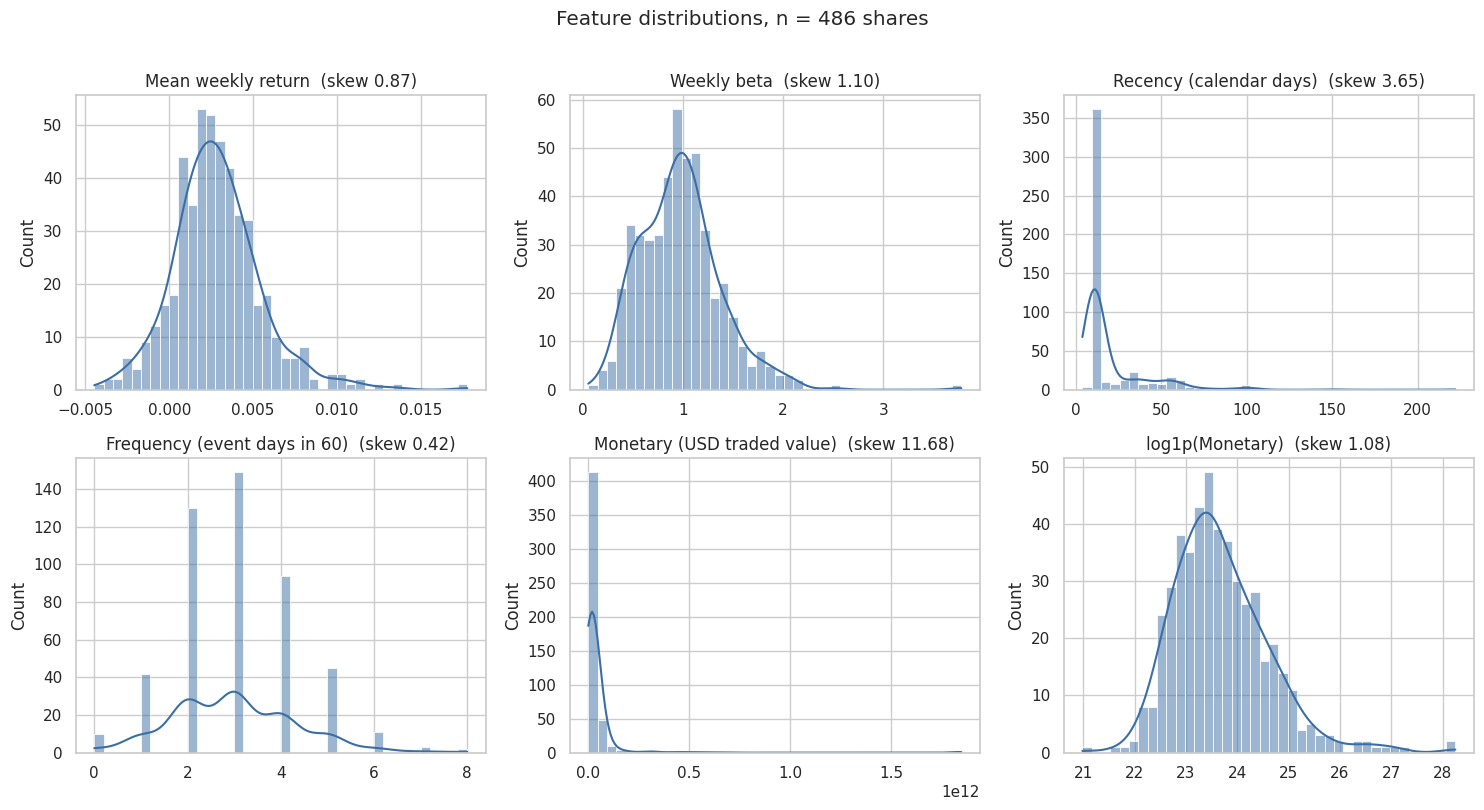

In [16]:
# ---- Independent verification: recompute every feature with separate, loop-based code ----
# A second implementation that shares no code with sections 1.3-1.4. If both agree on every
# share, the vectorised calculations are confirmed.
from collections import OrderedDict
start_ts, end_ts = pd.Timestamp(START), pd.Timestamp(END)

def weekly_series_loop(daily):
    weeks = OrderedDict()
    for d, p in daily.items():                              # last available price in each Fri-ending week
        friday = d + pd.Timedelta(days=(4 - d.weekday()) % 7)
        weeks[friday] = p
    keep = [(f, p) for f, p in weeks.items() if f - pd.Timedelta(days=4) >= start_ts and f < end_ts]
    return pd.Series([p for _, p in keep], index=[f for f, _ in keep])

bench_w = weekly_series_loop(adj[BENCHMARK])
bench_r = [bench_w.iloc[i] / bench_w.iloc[i - 1] - 1 for i in range(1, len(bench_w))]
diffs = {"mean_return": 0.0, "beta": 0.0, "R": 0, "F": 0, "M_rel": 0.0}
for t in included:
    w = weekly_series_loop(adj[t])
    assert w.index.equals(bench_w.index)
    r = [w.iloc[i] / w.iloc[i - 1] - 1 for i in range(1, len(w))]
    mean_r = sum(r) / len(r)
    beta_t = np.cov(r, bench_r, ddof=1)[0, 1] / np.var(bench_r, ddof=1)
    vols, closes, dates = V[t].to_numpy(), C[t].to_numpy(), V.index
    events = [i for i in range(BASELINE_SESSIONS, len(vols))
              if vols[i] > EVENT_MULTIPLE * vols[i - BASELINE_SESSIONS:i].mean()]
    R_t = (obs_date - dates[events[-1]]).days if events else np.nan
    F_t = sum(1 for i in events if i >= len(vols) - WINDOW_SESSIONS)
    M_t = float((closes[-WINDOW_SESSIONS:] * vols[-WINDOW_SESSIONS:]).sum())
    diffs["mean_return"] = max(diffs["mean_return"], abs(mean_r - rr.at[t, "Mean_Weekly_Return"]))
    diffs["beta"] = max(diffs["beta"], abs(beta_t - rr.at[t, "Weekly_Beta"]))
    if not (np.isnan(R_t) and np.isnan(rfm.at[t, "Recency_days"])):
        diffs["R"] = max(diffs["R"], abs(R_t - rfm.at[t, "Recency_days"]))
    diffs["F"] = max(diffs["F"], abs(F_t - rfm.at[t, "Frequency_days"]))
    diffs["M_rel"] = max(diffs["M_rel"], abs(M_t / rfm.at[t, "Monetary_USD"] - 1))

print(f"Shares re-checked: {len(included)}")
print("Largest disagreement between the two implementations:", {k: float(v) for k, v in diffs.items()})
assert diffs["mean_return"] < 1e-12 and diffs["beta"] < 1e-9 and diffs["R"] == 0 and diffs["F"] == 0 and diffs["M_rel"] < 1e-12
print("PASS: weekly returns, beta, Recency, Frequency and Monetary reproduced exactly by independent code.")

# ---- Feature summaries ----
summ = features.loc[common, FEATS5 + ["Log1p_Monetary"]].describe(percentiles=[.05, .25, .5, .75, .95]).T
summ["skew"] = features.loc[common, FEATS5 + ["Log1p_Monetary"]].skew()
summ["kurtosis"] = features.loc[common, FEATS5 + ["Log1p_Monetary"]].kurt()
summ.to_csv(f"{OUT_DIR}/feature_summary.csv")
display(summ.round(4))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
labels = {"Mean_Weekly_Return": "Mean weekly return", "Weekly_Beta": "Weekly beta",
          "Recency_days": "Recency (calendar days)", "Frequency_days": "Frequency (event days in 60)",
          "Monetary_USD": "Monetary (USD traded value)", "Log1p_Monetary": "log1p(Monetary)"}
for ax, col in zip(axes.ravel(), labels):
    sns.histplot(features.loc[common, col], bins=40, kde=True, ax=ax, color="#3b6ea5")
    ax.set_title(f"{labels[col]}  (skew {features.loc[common, col].skew():.2f})")
    ax.set_xlabel("")
plt.suptitle(f"Feature distributions, n = {len(common)} shares", y=1.01)
plt.tight_layout(); savefig("fig01_feature_distributions"); plt.show()

## 2.1 Feature preparation

Two separate matrices, each standardised on its own:

* **Risk-return:** mean weekly return, weekly beta
* **Trading activity:** Recency, Frequency, log1p(Monetary)

The five features are never combined into one score.

,skew,IQR_outliers,abs_z_gt_3
Mean_Weekly_Return,0.868,15.0,6.0
Weekly_Beta,1.104,10.0,2.0
Recency_days,3.646,115.0,11.0
Frequency_days,0.425,2.0,5.0
Monetary_USD,11.684,45.0,5.0
Log1p_Monetary,1.079,13.0,7.0


Most extreme shares (|z| > 3):
  Mean_Weekly_Return: CVNA, FIX, VST, VRT, NVDA, SMCI
  Weekly_Beta: XYZ, CVNA
  Recency_days: APD, MKC, FCX, AZO, CB, COR, DUK, HRL, MDT, WEC, NVDA
  Frequency_days: FOXA, UNH, XEL, CI, HSY
  Log1p_Monetary: AVGO, META, AMZN, MSFT, AAPL, NVDA, TSLA

Means after scaling: [0. 0.] [-0. -0. -0.]
SDs after scaling:   [1. 1.] [1. 1. 1.]


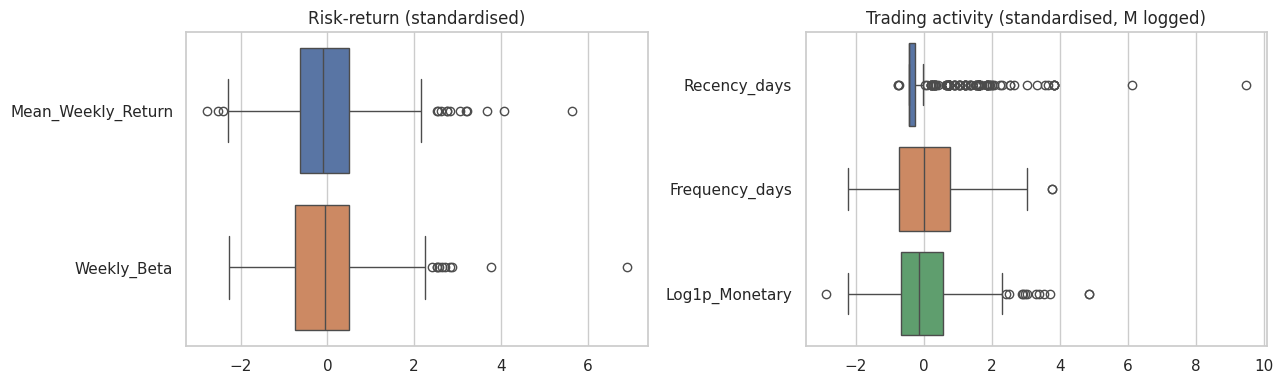

In [17]:
RR_COLS = ["Mean_Weekly_Return", "Weekly_Beta"]
RFM_RAW = ["Recency_days", "Frequency_days", "Monetary_USD"]
RFM_COLS = ["Recency_days", "Frequency_days", "Log1p_Monetary"]
df = features.loc[common].copy()

def outlier_table(frame):
    out = {}
    for c in frame:
        q1, q3 = frame[c].quantile([.25, .75]); iqr = q3 - q1
        z = (frame[c] - frame[c].mean()) / frame[c].std()
        out[c] = {"skew": frame[c].skew(),
                  "IQR_outliers": int(((frame[c] < q1 - 1.5 * iqr) | (frame[c] > q3 + 1.5 * iqr)).sum()),
                  "abs_z_gt_3": int((z.abs() > 3).sum())}
    return pd.DataFrame(out).T

ot = outlier_table(df[RR_COLS + RFM_RAW + ["Log1p_Monetary"]])
display(ot.round(3))
ot.to_csv(f"{OUT_DIR}/skew_outliers.csv")

print("Most extreme shares (|z| > 3):")
for c in RR_COLS + RFM_COLS:
    z = (df[c] - df[c].mean()) / df[c].std()
    ext = z[z.abs() > 3].sort_values()
    if len(ext): print(f"  {c}: {', '.join(ext.index)}")

scaler_rr, scaler_rfm = StandardScaler(), StandardScaler()
X_rr = scaler_rr.fit_transform(df[RR_COLS])
X_rfm = scaler_rfm.fit_transform(df[RFM_COLS])
print("\nMeans after scaling:", X_rr.mean(0).round(3), X_rfm.mean(0).round(3))
print("SDs after scaling:  ", X_rr.std(0).round(3), X_rfm.std(0).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=pd.DataFrame(X_rr, columns=RR_COLS), orient="h", ax=axes[0]); axes[0].set_title("Risk-return (standardised)")
sns.boxplot(data=pd.DataFrame(X_rfm, columns=RFM_COLS), orient="h", ax=axes[1]); axes[1].set_title("Trading activity (standardised, M logged)")
plt.tight_layout(); savefig("fig02_standardised_boxplots"); plt.show()

## 2.2 and 2.3 Ward agglomerative clustering and K-means, k = 2 to 8

Both algorithms are fitted to both matrices, giving **four baseline solutions** (week 4 lecture: hierarchical vs partitioning models).

* **Ward**: agglomerative, merges the pair giving the smallest increase in within-cluster variance; greedy, so early merges are never reversed; a dendrogram shows the nested structure.
* **K-means**: hard partitioning around centroids, minimises inertia (WCSS); k-means++ initialisation and multiple runs reduce the risk of a poor local minimum; sensitive to scaling and outliers because distances are squared. For every k the notebook reports the silhouette score, cluster sizes and (for K-means) inertia. The selected k is chosen from this evidence and the interpretability of the profiles, not from the dendrogram colour threshold.

In [18]:
def ward_scan(X):
    Z = linkage(X, method="ward", metric="euclidean")
    rows, labels = [], {}
    for k in K_RANGE:
        lab = cut_tree(Z, n_clusters=k).ravel() + 1   # same cut as the seminar code
        sizes = np.bincount(lab)[1:]
        labels[k] = lab
        rows.append({"k": k, "silhouette": silhouette_score(X, lab),
                     "min_size": sizes.min(), "max_size": sizes.max(), "sizes": sorted(sizes.tolist(), reverse=True),
                     "merge_height": Z[-(k - 1), 2]})
    return Z, pd.DataFrame(rows).set_index("k"), labels

def kmeans_scan(X):
    rows, labels = [], {}
    for k in K_RANGE:
        km = KMeans(n_clusters=k, init="k-means++", n_init=KMEANS_N_INIT, random_state=SEED).fit(X)
        sizes = np.bincount(km.labels_)
        labels[k] = km.labels_ + 1
        rows.append({"k": k, "silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_,
                     "min_size": sizes.min(), "max_size": sizes.max(), "sizes": sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index("k"), labels

def suggest_k(table, min_share=0.05):
    # highest silhouette among k whose smallest cluster holds at least 5% of shares
    ok = table[table["min_size"] >= min_share * len(common)]
    return int((ok if len(ok) else table)["silhouette"].idxmax())

Z_rr, ward_rr_tab, ward_rr_lab = ward_scan(X_rr)
Z_rfm, ward_rfm_tab, ward_rfm_lab = ward_scan(X_rfm)
km_rr_tab, km_rr_lab = kmeans_scan(X_rr)
km_rfm_tab, km_rfm_lab = kmeans_scan(X_rfm)

for name, tab in [("Ward - risk/return", ward_rr_tab), ("Ward - RFM", ward_rfm_tab),
                  ("K-means - risk/return", km_rr_tab), ("K-means - RFM", km_rfm_tab)]:
    print(f"\n{name}  (suggested k = {suggest_k(tab)})")
    display(tab.round(3))
    tab.to_csv(f"{OUT_DIR}/scan_{name.replace(' ', '').replace('/', '').replace('-', '_')}.csv")


Ward - risk/return  (suggested k = 2)


,silhouette,min_size,max_size,sizes,merge_height
k,,,,,
2,0.339,92,394,"[394, 92]",23.073
3,0.274,92,230,"[230, 164, 92]",18.803
4,0.282,48,182,"[182, 164, 92, 48]",14.210
5,0.304,48,182,"[182, 98, 92, 66, 48]",12.669
6,0.320,5,182,"[182, 98, 87, 66, 48, 5]",11.601
7,0.324,5,160,"[160, 98, 87, 66, 48, 22, 5]",8.342
8,0.321,5,160,"[160, 98, 66, 56, 48, 31, 22, 5]",8.308



Ward - RFM  (suggested k = 2)


,silhouette,min_size,max_size,sizes,merge_height
k,,,,,
2,0.368,82,404,"[404, 82]",26.706
3,0.304,82,250,"[250, 154, 82]",22.985
4,0.289,43,207,"[207, 154, 82, 43]",15.843
5,0.305,10,207,"[207, 154, 72, 43, 10]",15.152
6,0.314,10,207,"[207, 136, 72, 43, 18, 10]",13.580
7,0.292,10,141,"[141, 136, 72, 66, 43, 18, 10]",11.293
8,0.302,10,141,"[141, 79, 72, 66, 57, 43, 18, 10]",10.537



K-means - risk/return  (suggested k = 2)


,silhouette,inertia,min_size,max_size,sizes
k,,,,,
2,0.387,621.634,143,343,"[343, 143]"
3,0.329,461.179,119,202,"[202, 165, 119]"
4,0.327,371.577,40,160,"[160, 154, 132, 40]"
5,0.341,309.613,27,166,"[166, 131, 112, 50, 27]"
6,0.335,265.097,5,156,"[156, 127, 105, 50, 43, 5]"
7,0.328,227.183,5,128,"[128, 103, 85, 77, 47, 41, 5]"
8,0.354,194.362,5,136,"[136, 79, 78, 76, 43, 40, 29, 5]"



K-means - RFM  (suggested k = 2)


,silhouette,inertia,min_size,max_size,sizes
k,,,,,
2,0.423,1066.832,68,418,"[418, 68]"
3,0.325,796.614,64,270,"[270, 152, 64]"
4,0.341,609.832,61,212,"[212, 122, 91, 61]"
5,0.358,514.714,11,198,"[198, 122, 87, 68, 11]"
6,0.347,437.393,11,143,"[143, 120, 105, 67, 40, 11]"
7,0.347,386.286,1,141,"[141, 120, 104, 68, 41, 11, 1]"
8,0.350,342.175,1,140,"[140, 106, 83, 66, 64, 15, 11, 1]"


Ward RR: ARI cut_tree vs fcluster for k=2..8 -> [1. 1. 1. 1. 1. 1. 1.]
Ward RFM: ARI cut_tree vs fcluster for k=2..8 -> [1. 1. 1. 1. 1. 1. 1.]


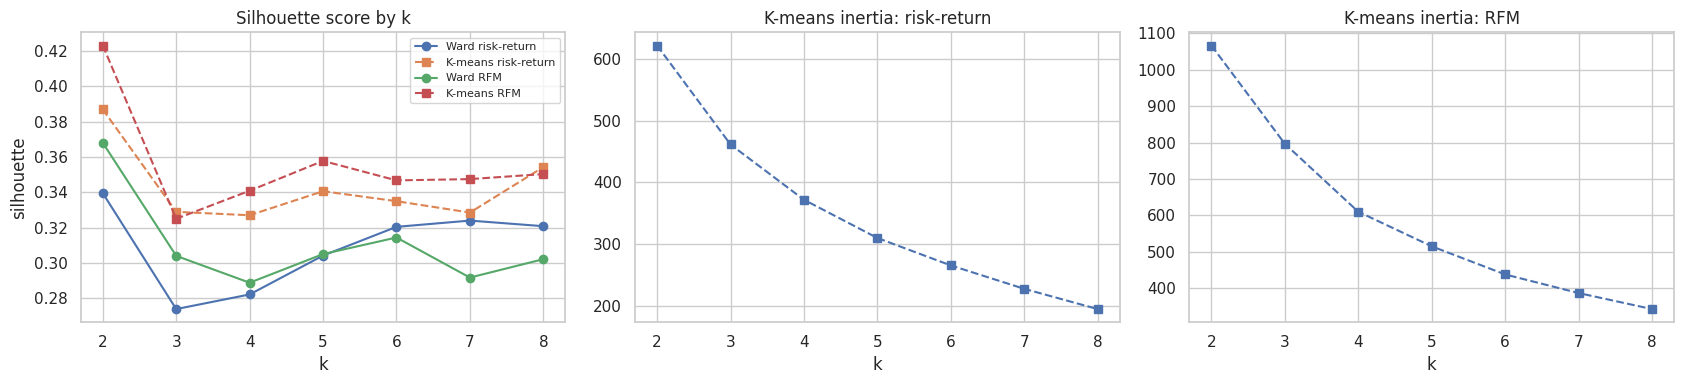

In [19]:
# Cross-check: scipy cut_tree (seminar code) and fcluster must give identical Ward partitions
for name, Z, labs in [("RR", Z_rr, ward_rr_lab), ("RFM", Z_rfm, ward_rfm_lab)]:
    agree = [adjusted_rand_score(labs[k], fcluster(Z, k, criterion="maxclust")) for k in K_RANGE]
    print(f"Ward {name}: ARI cut_tree vs fcluster for k=2..8 ->", np.round(agree, 3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for tab, lbl, mk in [(ward_rr_tab, "Ward risk-return", "o-"), (km_rr_tab, "K-means risk-return", "s--"),
                     (ward_rfm_tab, "Ward RFM", "o-"), (km_rfm_tab, "K-means RFM", "s--")]:
    axes[0].plot(tab.index, tab["silhouette"], mk, label=lbl)
axes[0].set(title="Silhouette score by k", xlabel="k", ylabel="silhouette"); axes[0].legend(fontsize=8)
axes[1].plot(km_rr_tab.index, km_rr_tab["inertia"], "s--"); axes[1].set(title="K-means inertia: risk-return", xlabel="k")
axes[2].plot(km_rfm_tab.index, km_rfm_tab["inertia"], "s--"); axes[2].set(title="K-means inertia: RFM", xlabel="k")
plt.tight_layout(); savefig("fig03_silhouette_inertia"); plt.show()

### Select the cluster counts

The defaults below are the highest-silhouette k whose smallest cluster holds at least 5% of the shares. **Review the tables, the dendrograms and the profiles, then override a value if a different k gives clearer and more useful groups.** Record the reason in the report.

In [20]:
# Silhouette alone favours k = 2 for every solution, but k = 2 only splits each matrix on one feature.
# Final choices weigh silhouette, cluster sizes, K-means bootstrap stability and interpretability,
# and use the same k for both algorithms so their memberships can be compared directly (ARI).
#
# Risk-return, k = 3: three beta tiers (defensive / market-like / high-beta) with every cluster > 19% of shares.
#   K-means stability stays high (bootstrap ARI 0.86 vs 0.71 at k = 4), and mean weekly returns are mostly
#   estimation noise (section 2.6A), so finer splits along the return axis would chase noise.
# RFM, k = 4: at k = 2 the clusters explain ~0% of log1p(M) and 9% of F, i.e. a Recency-only split.
#   k = 4 lets all three features shape the groups (eta-squared R 0.66, F 0.57, M 0.52 for K-means),
#   gives the most stable K-means solution of k = 2..8 (bootstrap ARI 0.94), and the smallest cluster
#   still holds 61 shares (12.6%). The cost is a lower silhouette (0.341 vs 0.423).
print("Data-driven suggestion (max silhouette, min size 5%):",
      {"Ward_RR": suggest_k(ward_rr_tab), "Ward_RFM": suggest_k(ward_rfm_tab),
       "KMeans_RR": suggest_k(km_rr_tab), "KMeans_RFM": suggest_k(km_rfm_tab)})
K_WARD_RR = K_KM_RR = 3
K_WARD_RFM = K_KM_RFM = 4
print("Selected k -> Ward RR:", K_WARD_RR, "| Ward RFM:", K_WARD_RFM, "| K-means RR:", K_KM_RR, "| K-means RFM:", K_KM_RFM)

Data-driven suggestion (max silhouette, min size 5%): {'Ward_RR': 2, 'Ward_RFM': 2, 'KMeans_RR': 2, 'KMeans_RFM': 2}
Selected k -> Ward RR: 3 | Ward RFM: 4 | K-means RR: 3 | K-means RFM: 4


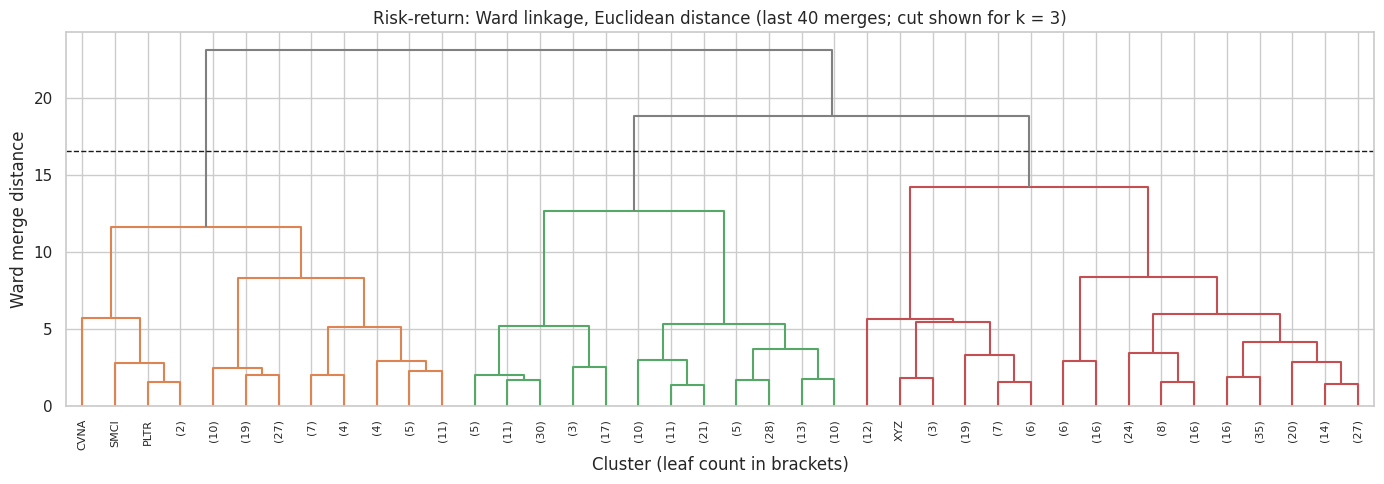

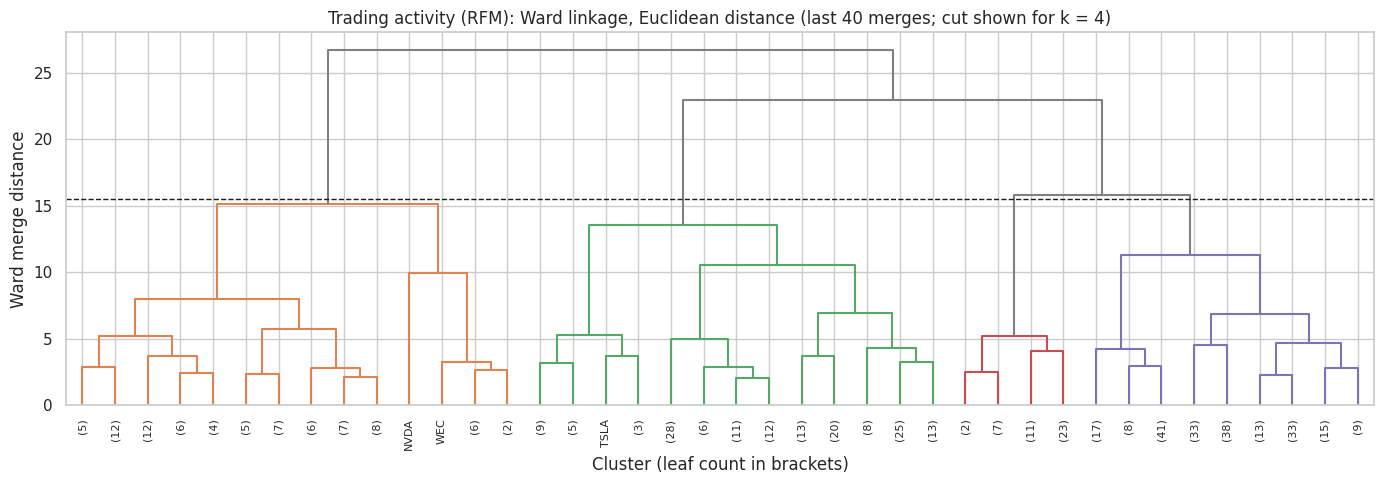

In [21]:
def plot_dendrogram(Z, k, title, fname):
    cut = (Z[-k, 2] + Z[-(k - 1), 2]) / 2      # height that yields exactly k groups
    plt.figure(figsize=(14, 5))
    dendrogram(Z, truncate_mode="lastp", p=40, show_leaf_counts=True, leaf_rotation=90, labels=list(common),
               color_threshold=cut, above_threshold_color="grey")
    plt.axhline(cut, ls="--", c="k", lw=1)
    plt.title(f"{title}: Ward linkage, Euclidean distance (last 40 merges; cut shown for k = {k})")
    plt.ylabel("Ward merge distance"); plt.xlabel("Cluster (leaf count in brackets)")
    plt.tight_layout(); savefig(fname); plt.show()

plot_dendrogram(Z_rr, K_WARD_RR, "Risk-return", "fig04_dendrogram_risk_return")
plot_dendrogram(Z_rfm, K_WARD_RFM, "Trading activity (RFM)", "fig05_dendrogram_rfm")

In [22]:
# K-means stability: does the selected solution change with the random seed?
def seed_stability(X, k, seeds=range(10)):
    ref = KMeans(n_clusters=k, n_init=KMEANS_N_INIT, random_state=SEED).fit_predict(X)
    return np.mean([adjusted_rand_score(ref, KMeans(n_clusters=k, n_init=KMEANS_N_INIT, random_state=s).fit_predict(X))
                    for s in seeds])
stab = {"K-means RR": float(seed_stability(X_rr, K_KM_RR)), "K-means RFM": float(seed_stability(X_rfm, K_KM_RFM))}
print("Mean ARI against the seed-42 solution across 10 other seeds:", {k: round(v, 3) for k, v in stab.items()})

Mean ARI against the seed-42 solution across 10 other seeds: {'K-means RR': 1.0, 'K-means RFM': 0.998}


## 2.4 Cluster profiles and algorithm comparison

Cluster numbers are arbitrary. They are re-ordered here so that, within each feature space, cluster 1 has the lowest beta (risk-return) or the lowest median traded value (RFM). This makes tables easier to read but does not imply any ranking.

In [23]:
def relabel(labels, key_values):
    # renumber clusters 1..k by ascending median of key_values
    s = pd.Series(labels, index=common)
    order = key_values.groupby(s).median().sort_values().index
    return s.map({old: new for new, old in enumerate(order, start=1)})

df["Ward_RR"] = relabel(ward_rr_lab[K_WARD_RR], df["Weekly_Beta"])
df["KMeans_RR"] = relabel(km_rr_lab[K_KM_RR], df["Weekly_Beta"])
df["Ward_RFM"] = relabel(ward_rfm_lab[K_WARD_RFM], df["Monetary_USD"])
df["KMeans_RFM"] = relabel(km_rfm_lab[K_KM_RFM], df["Monetary_USD"])

def profile(col):
    g = df.groupby(col)
    p = pd.DataFrame({
        "n": g.size(),
        "share_%": (g.size() / len(df) * 100).round(1),
        "mean_wkly_ret_%": g["Mean_Weekly_Return"].mean() * 100,
        "median_wkly_ret_%": g["Mean_Weekly_Return"].median() * 100,
        "mean_beta": g["Weekly_Beta"].mean(),
        "median_beta": g["Weekly_Beta"].median(),
        "median_R_days": g["Recency_days"].median(),
        "mean_F_days": g["Frequency_days"].mean(),
        "median_M_$bn": g["Monetary_USD"].median() / 1e9,
        "mean_M_$bn": g["Monetary_USD"].mean() / 1e9,
        "top_sector": g["Sector"].agg(lambda s: f"{s.value_counts().index[0]} ({s.value_counts(normalize=True).iloc[0]:.0%})"),
    })
    return p.round(3)

profiles = {}
for col in ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]:
    profiles[col] = profile(col)
    print(f"\n{col} profile (original units)")
    display(profiles[col])
    profiles[col].to_csv(f"{OUT_DIR}/profile_{col}.csv")


Ward_RR profile (original units)


,n,share_%,mean_wkly_ret_%,median_wkly_ret_%,mean_beta,median_beta,median_R_days,mean_F_days,median_M_$bn,mean_M_$bn,top_sector
Ward_RR,,,,,,,,,,,
1,164,33.7,0.287,0.327,0.601,0.578,11.0,2.780,17.649,25.173,Financials (18%)
2,230,47.3,0.146,0.171,1.110,1.038,11.0,3.057,14.111,33.801,Industrials (19%)
3,92,18.9,0.632,0.550,1.298,1.218,11.0,3.196,24.184,78.781,Information Technology (32%)



KMeans_RR profile (original units)


,n,share_%,mean_wkly_ret_%,median_wkly_ret_%,mean_beta,median_beta,median_R_days,mean_F_days,median_M_$bn,mean_M_$bn,top_sector
KMeans_RR,,,,,,,,,,,
1,202,41.6,0.259,0.259,0.631,0.622,11.0,2.911,15.202,23.440,Financials (17%)
2,165,34.0,0.095,0.118,1.139,1.081,11.0,3.006,14.562,24.596,Information Technology (19%)
3,119,24.5,0.596,0.528,1.326,1.221,11.0,3.101,25.227,87.037,Information Technology (33%)



Ward_RFM profile (original units)


,n,share_%,mean_wkly_ret_%,median_wkly_ret_%,mean_beta,median_beta,median_R_days,mean_F_days,median_M_$bn,mean_M_$bn,top_sector
Ward_RFM,,,,,,,,,,,
1,207,42.6,0.247,0.244,0.926,0.924,11.0,2.942,10.785,11.100,Industrials (19%)
2,43,8.8,0.281,0.276,1.008,1.047,11.0,5.372,14.430,14.962,Industrials (26%)
3,82,16.9,0.286,0.244,1.009,1.047,54.5,2.098,17.849,47.159,Information Technology (22%)
4,154,31.7,0.338,0.325,1.010,0.989,11.0,2.864,39.695,80.145,Information Technology (20%)



KMeans_RFM profile (original units)


,n,share_%,mean_wkly_ret_%,median_wkly_ret_%,mean_beta,median_beta,median_R_days,mean_F_days,median_M_$bn,mean_M_$bn,top_sector
KMeans_RFM,,,,,,,,,,,
1,122,25.1,0.257,0.253,0.966,0.922,11.0,4.549,12.826,15.015,Industrials (20%)
2,212,43.6,0.275,0.259,0.939,0.931,11.0,2.368,13.336,15.175,Industrials (20%)
3,61,12.6,0.300,0.253,0.975,1.051,55.0,1.672,21.242,56.180,Information Technology (21%)
4,91,18.7,0.341,0.295,1.064,1.048,11.0,3.231,60.183,117.301,Information Technology (27%)


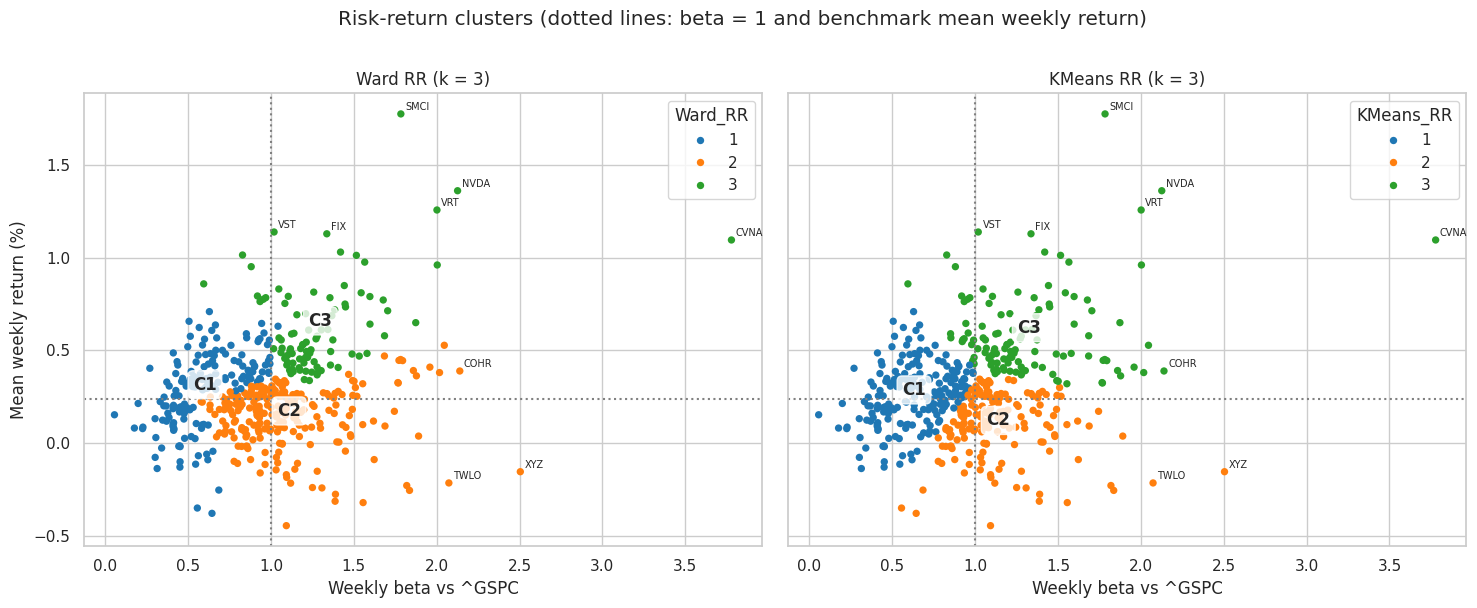

In [24]:
# Risk-return: only two features, so they are plotted directly in original units (no reduction needed)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, col in zip(axes, ["Ward_RR", "KMeans_RR"]):
    sns.scatterplot(data=df, x="Weekly_Beta", y=df["Mean_Weekly_Return"] * 100, hue=col,
                    palette="tab10", s=28, ax=ax, edgecolor="none")
    for c, g in df.groupby(col):
        ax.annotate(f"C{c}", (g["Weekly_Beta"].mean(), g["Mean_Weekly_Return"].mean() * 100),
                    fontsize=12, weight="bold", ha="center",
                    bbox=dict(boxstyle="round", fc="white", alpha=.8))
    ext = df.loc[(df["Weekly_Beta"].rank(pct=True) > .99) | (df["Mean_Weekly_Return"].abs().rank(pct=True) > .99)]
    for t, r in ext.iterrows():
        ax.annotate(t, (r["Weekly_Beta"], r["Mean_Weekly_Return"] * 100), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.axvline(1, ls=":", c="grey"); ax.axhline(bench_ret.mean() * 100, ls=":", c="grey")
    ax.set(title=f"{col.replace('_', ' ')} (k = {df[col].nunique()})", xlabel="Weekly beta vs ^GSPC",
           ylabel="Mean weekly return (%)")
plt.suptitle("Risk-return clusters (dotted lines: beta = 1 and benchmark mean weekly return)", y=1.01)
plt.tight_layout(); savefig("fig06_risk_return_clusters"); plt.show()

PCA explained variance: PC1 45.8%, PC2 33.6%, total 79.4%


,PC1,PC2
Recency_days,0.711,0.023
Frequency_days,-0.650,0.402
Log1p_Monetary,0.268,0.915


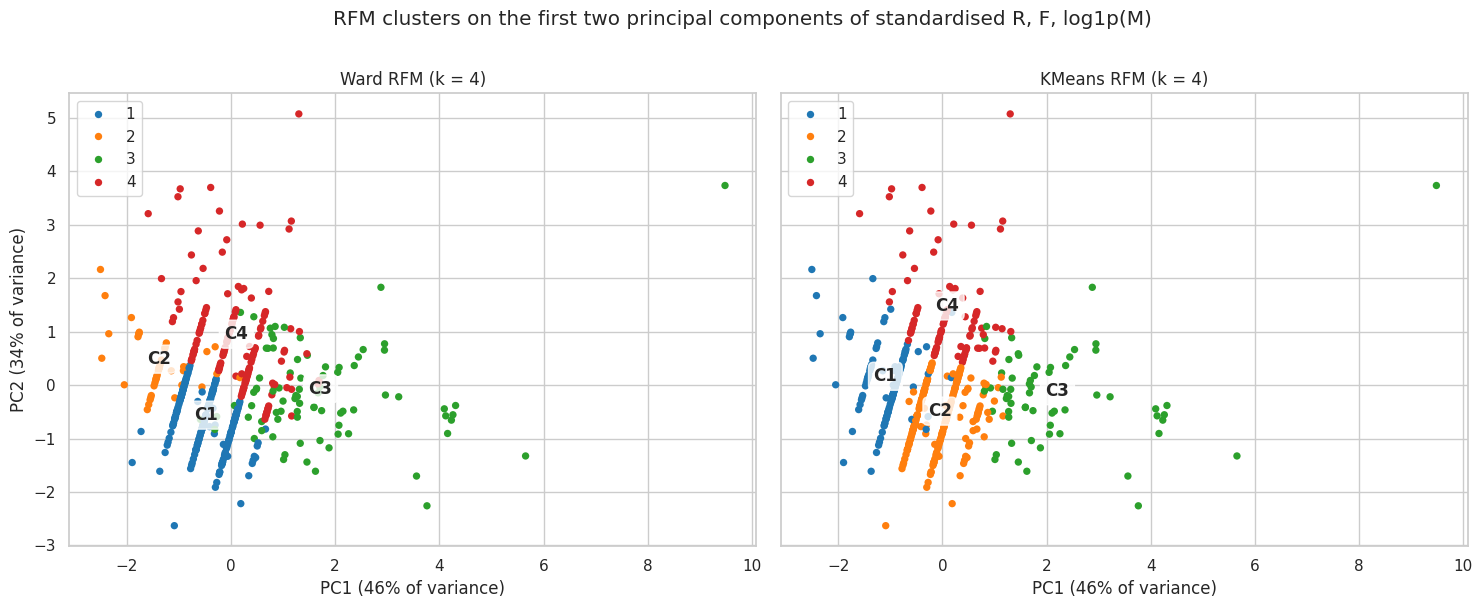

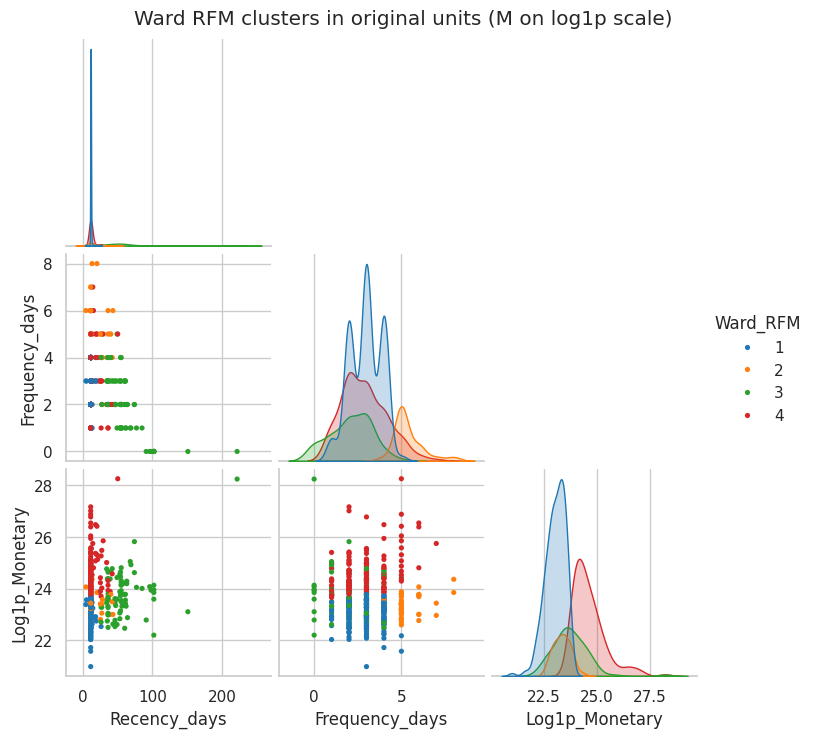

In [25]:
# RFM: three features -> PCA to 2-D for display only (clustering used all three standardised features)
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
P = pca.transform(X_rfm)
evr = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=RFM_COLS, columns=["PC1", "PC2"])
print(f"PCA explained variance: PC1 {evr[0]:.1%}, PC2 {evr[1]:.1%}, total {evr.sum():.1%}")
display(loadings.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, col in zip(axes, ["Ward_RFM", "KMeans_RFM"]):
    sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df[col].to_numpy(), palette="tab10", s=28, ax=ax, edgecolor="none")
    for c in sorted(df[col].unique()):
        m = (df[col] == c).to_numpy()
        ax.annotate(f"C{c}", P[m].mean(0), fontsize=12, weight="bold", ha="center",
                    bbox=dict(boxstyle="round", fc="white", alpha=.8))
    ax.set(title=f"{col.replace('_', ' ')} (k = {df[col].nunique()})",
           xlabel=f"PC1 ({evr[0]:.0%} of variance)", ylabel=f"PC2 ({evr[1]:.0%} of variance)")
plt.suptitle("RFM clusters on the first two principal components of standardised R, F, log1p(M)", y=1.01)
plt.tight_layout(); savefig("fig07_rfm_clusters_pca"); plt.show()

# Original-unit view of the same clusters
g = sns.pairplot(df[["Recency_days", "Frequency_days", "Log1p_Monetary", "Ward_RFM"]], hue="Ward_RFM",
                 palette="tab10", plot_kws=dict(s=14, edgecolor="none"), corner=True, height=2.4)
g.figure.suptitle("Ward RFM clusters in original units (M on log1p scale)", y=1.02)
savefig("fig08_rfm_pairplot"); plt.show()

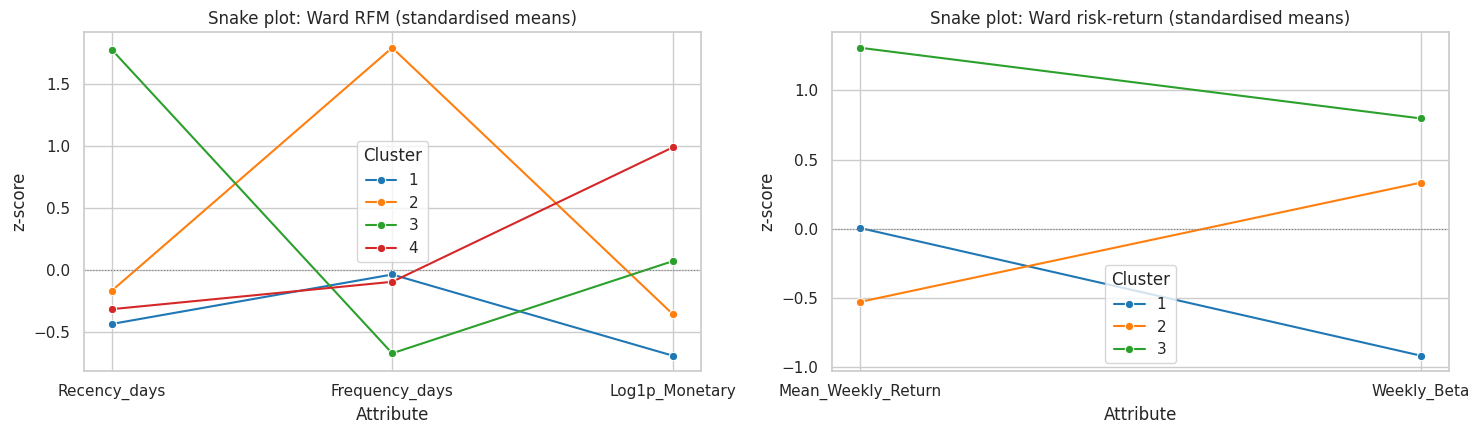

Note: higher Recency (days) means LESS recent activity, unlike F and M.


,ARI
Ward vs K-means (risk-return),0.516
Ward vs K-means (RFM),0.343
Risk-return vs RFM (Ward),0.024
Risk-return vs RFM (K-means),0.012


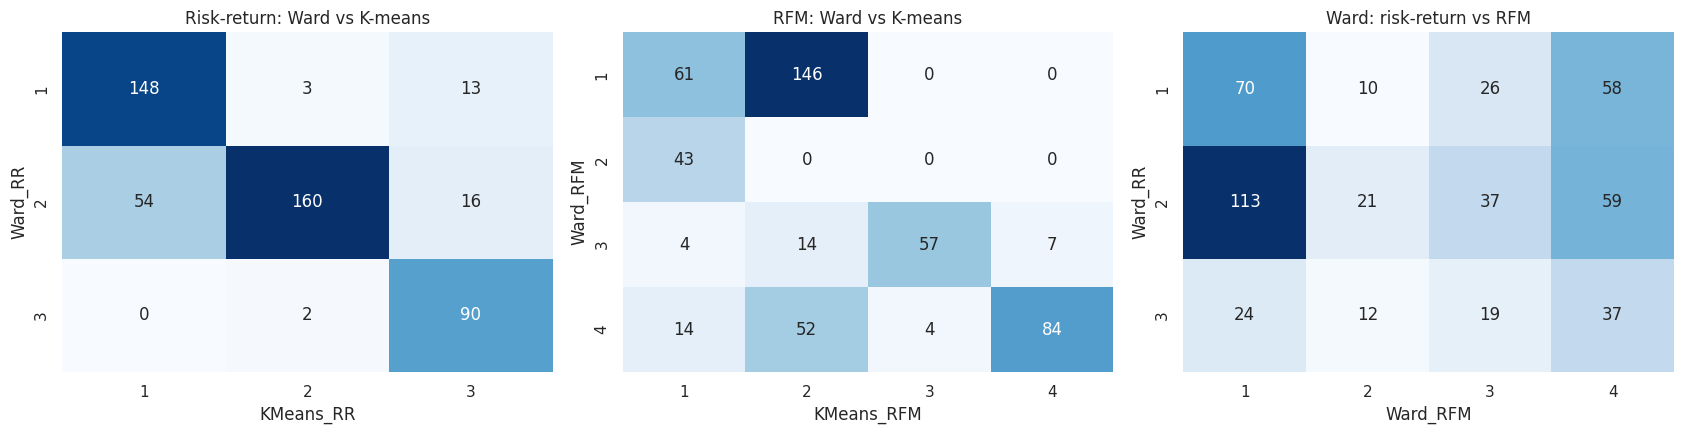

In [26]:
# Snake plot of standardised cluster profiles (as in the RFM_Kmeans seminar notebook)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (col, X, cols, title) in zip(axes, [("Ward_RFM", X_rfm, RFM_COLS, "Ward RFM"),
                                           ("Ward_RR", X_rr, RR_COLS, "Ward risk-return")]):
    z = pd.DataFrame(X, columns=cols, index=df.index)
    z["Cluster"] = df[col]
    melt = z.reset_index().melt(id_vars=["Ticker", "Cluster"], value_vars=cols, var_name="Attribute", value_name="Value")
    sns.lineplot(data=melt, x="Attribute", y="Value", hue="Cluster", palette="tab10", marker="o", ax=ax, errorbar=None)
    ax.axhline(0, c="grey", lw=.8, ls=":")
    ax.set(title=f"Snake plot: {title} (standardised means)", ylabel="z-score")
plt.tight_layout(); savefig("fig08b_snake_plots"); plt.show()
print("Note: higher Recency (days) means LESS recent activity, unlike F and M.")

# Algorithm comparison on the same shares
ari = pd.Series({
    "Ward vs K-means (risk-return)": adjusted_rand_score(df["Ward_RR"], df["KMeans_RR"]),
    "Ward vs K-means (RFM)": adjusted_rand_score(df["Ward_RFM"], df["KMeans_RFM"]),
    "Risk-return vs RFM (Ward)": adjusted_rand_score(df["Ward_RR"], df["Ward_RFM"]),
    "Risk-return vs RFM (K-means)": adjusted_rand_score(df["KMeans_RR"], df["KMeans_RFM"]),
}, name="ARI")
display(ari.round(3).to_frame())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (a, b, t) in zip(axes, [("Ward_RR", "KMeans_RR", "Risk-return: Ward vs K-means"),
                                ("Ward_RFM", "KMeans_RFM", "RFM: Ward vs K-means"),
                                ("Ward_RR", "Ward_RFM", "Ward: risk-return vs RFM")]):
    sns.heatmap(pd.crosstab(df[a], df[b]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(t)
plt.tight_layout(); savefig("fig09_membership_crosstabs"); plt.show()

## 2.5 RFM sensitivity and correlated inputs

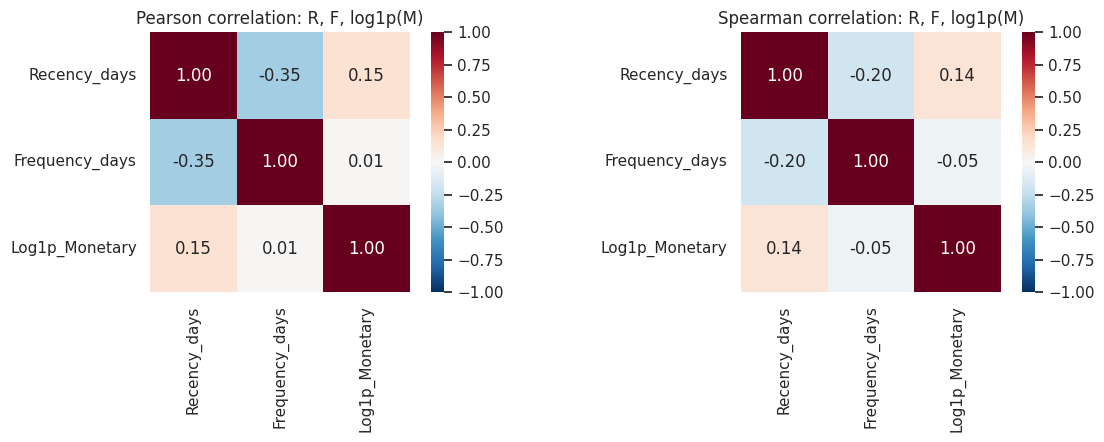

,Recency_days,Frequency_days,Log1p_Monetary
Recency_days,1.000,-0.346,0.152
Frequency_days,-0.346,1.000,0.013
Log1p_Monetary,0.152,0.013,1.000


,Recency_days,Frequency_days,Log1p_Monetary
Recency_days,1.000,-0.196,0.137
Frequency_days,-0.196,1.000,-0.048
Log1p_Monetary,0.137,-0.048,1.000


In [27]:
corr_p = df[RFM_COLS].corr(method="pearson")
corr_s = df[RFM_COLS].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, c, t in [(axes[0], corr_p, "Pearson"), (axes[1], corr_s, "Spearman")]:
    sns.heatmap(c, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r", ax=ax, square=True)
    ax.set_title(f"{t} correlation: R, F, log1p(M)")
plt.tight_layout(); savefig("fig10_rfm_correlations"); plt.show()
pd.concat({"pearson": corr_p, "spearman": corr_s}).to_csv(f"{OUT_DIR}/rfm_correlations.csv")
display(corr_p.round(3)); display(corr_s.round(3))

ARI, Ward RFM vs Ward R+F only (k = 4): 0.203
Silhouette of R+F-only solution: 0.516

Share of each feature's variance explained by cluster membership (eta-squared):


,Ward RFM (with M),Ward R+F only
Recency_days,0.648,0.831
Frequency_days,0.364,0.596
Log1p_Monetary,0.524,0.005


Traded-value profiles of the two solutions:


n  median_M_bn  mean_F  median_R
          Ward_RFM                                    
With M    1         207        10.79    2.94      11.0
          2          43        14.43    5.37      11.0
          3          82        17.85    2.10      54.5
          4         154        39.70    2.86      11.0
Without M 1         272        14.86    3.86      11.0
          2         125        17.70    1.80      11.0
          3          79        20.13    2.27      49.0
          4          10        23.79    0.00     102.0

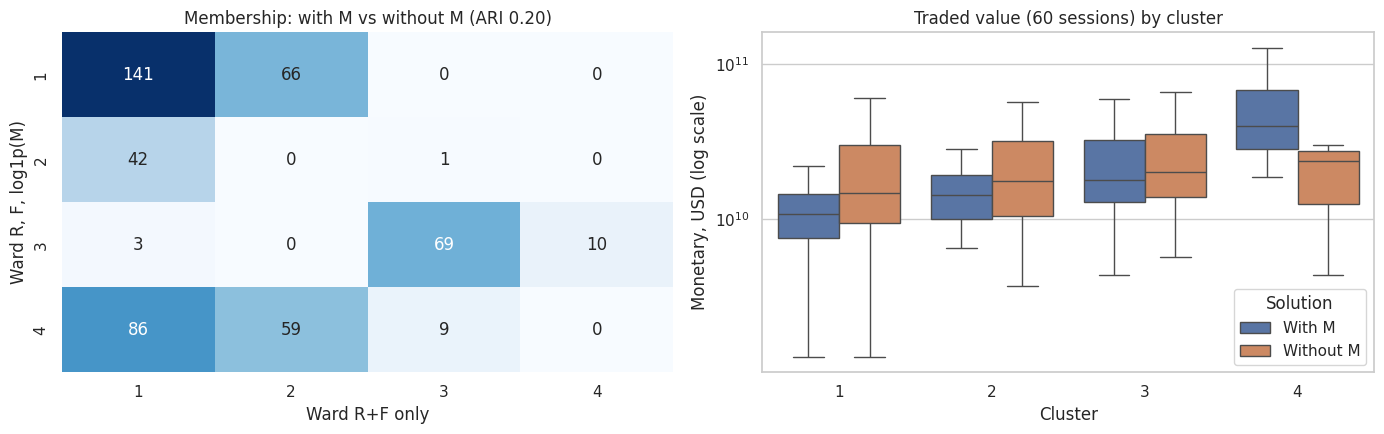

In [28]:
# How much of each standardised feature's variance do the clusters explain? (eta-squared)
def eta_squared(Xs, cols, labels):
    Xs = pd.DataFrame(Xs, columns=cols)
    out = {}
    for c in cols:
        total = ((Xs[c] - Xs[c].mean()) ** 2).sum()
        between = sum(len(g) * (g.mean() - Xs[c].mean()) ** 2 for _, g in Xs[c].groupby(np.asarray(labels)))
        out[c] = between / total
    return pd.Series(out)

# 2.5.2 Repeat the selected Ward RFM solution with R and F only (same shares, same k, fresh scaling)
RF_COLS = ["Recency_days", "Frequency_days"]
X_rf = StandardScaler().fit_transform(df[RF_COLS])
Z_rf = linkage(X_rf, method="ward", metric="euclidean")
df["Ward_RF_only"] = relabel(cut_tree(Z_rf, n_clusters=K_WARD_RFM).ravel() + 1, df["Monetary_USD"])

ari_m = adjusted_rand_score(df["Ward_RFM"], df["Ward_RF_only"])
print(f"ARI, Ward RFM vs Ward R+F only (k = {K_WARD_RFM}): {ari_m:.3f}")
print(f"Silhouette of R+F-only solution: {silhouette_score(X_rf, df['Ward_RF_only']):.3f}")

eta = pd.DataFrame({
    "Ward RFM (with M)": eta_squared(X_rfm, RFM_COLS, df["Ward_RFM"]),
    "Ward R+F only": eta_squared(scaler_rfm.transform(df[RFM_COLS]), RFM_COLS, df["Ward_RF_only"]),
})
print("\nShare of each feature's variance explained by cluster membership (eta-squared):")
display(eta.round(3))

tv = pd.concat({
    "With M": df.groupby("Ward_RFM").agg(n=("Monetary_USD", "size"), median_M_bn=("Monetary_USD", lambda s: s.median() / 1e9),
                                          mean_F=("Frequency_days", "mean"), median_R=("Recency_days", "median")),
    "Without M": df.groupby("Ward_RF_only").agg(n=("Monetary_USD", "size"), median_M_bn=("Monetary_USD", lambda s: s.median() / 1e9),
                                                mean_F=("Frequency_days", "mean"), median_R=("Recency_days", "median")),
})
print("Traded-value profiles of the two solutions:")
display(tv.round(2))
tv.to_csv(f"{OUT_DIR}/monetary_removal_profiles.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(pd.crosstab(df["Ward_RFM"], df["Ward_RF_only"]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title=f"Membership: with M vs without M (ARI {ari_m:.2f})", xlabel="Ward R+F only", ylabel="Ward R, F, log1p(M)")
plot_df = pd.concat([df[["Monetary_USD"]].assign(Solution="With M", Cluster=df["Ward_RFM"]),
                     df[["Monetary_USD"]].assign(Solution="Without M", Cluster=df["Ward_RF_only"])])
sns.boxplot(data=plot_df, x="Cluster", y="Monetary_USD", hue="Solution", ax=axes[1], showfliers=False)
axes[1].set_yscale("log"); axes[1].set(title="Traded value (60 sessions) by cluster", ylabel="Monetary, USD (log scale)")
plt.tight_layout(); savefig("fig11_monetary_removal"); plt.show()

In [29]:
# Robustness (optional extension): does log-transforming Recency change the Ward RFM solution?
X_alt = StandardScaler().fit_transform(df[RFM_COLS].assign(Recency_days=np.log1p(df["Recency_days"])))
alt = cut_tree(linkage(X_alt, method="ward"), n_clusters=K_WARD_RFM).ravel() + 1
print(f"ARI, baseline Ward RFM vs Ward RFM with log1p(R): {adjusted_rand_score(df['Ward_RFM'], alt):.3f}")

ARI, baseline Ward RFM vs Ward RFM with log1p(R): 0.757


## 2.6 Evidence for the critical review (Task 3.2.3)

These checks test the limitations the brief raises, so they can be discussed with evidence rather than asserted:

* **A. Estimation noise:** are mean weekly returns and betas precise enough to separate shares?
* **B. Return dependencies:** do low-beta clusters actually diversify, or are their returns still correlated with each other?
* **C. Event clustering in time:** is Recency driven by market-wide calendar days (index rebalancing, option expiry, elections) rather than share-specific news?
* **D. Cluster stability:** do the selected Ward solutions survive resampling of shares?
* **E. Survivorship:** does the surviving-constituent set outperform the index?
* **F. Size proxy:** does Monetary mostly reflect company size or price level?

In [30]:
# A. Standard errors of mean weekly return and beta
n_w = len(bench_ret)
se = pd.DataFrame(index=common)
se["mean_ret_SE"] = df["Weekly_Volatility"] / np.sqrt(n_w)
se["mean_ret_t"] = df["Mean_Weekly_Return"] / se["mean_ret_SE"]
resid_var = {}
for t in common:
    b = df.at[t, "Weekly_Beta"]; a = share_ret[t].mean() - b * bench_ret.mean()
    resid_var[t] = ((share_ret[t] - a - b * bench_ret) ** 2).sum() / (n_w - 2)
se["beta_SE"] = np.sqrt(pd.Series(resid_var) / ((bench_ret - bench_ret.mean()) ** 2).sum())
print(f"Shares whose mean weekly return is significantly non-zero (|t| > 1.96): "
      f"{(se['mean_ret_t'].abs() > 1.96).sum()} of {len(se)}")
print(f"Median SE of mean weekly return: {se['mean_ret_SE'].median()*100:.3f} pp "
      f"vs cross-sectional SD of mean returns: {df['Mean_Weekly_Return'].std()*100:.3f} pp")
print(f"Median SE of beta: {se['beta_SE'].median():.3f} vs cross-sectional SD of beta: {df['Weekly_Beta'].std():.3f}")
# signal-to-noise: share of cross-sectional variance that is not estimation noise
for col, s in [("Mean_Weekly_Return", "mean_ret_SE"), ("Weekly_Beta", "beta_SE")]:
    reliab = 1 - (se[s] ** 2).mean() / df[col].var()
    print(f"Reliability of {col} (1 - noise variance / total variance): {reliab:.2f}")
se.to_csv(f"{OUT_DIR}/estimation_noise.csv")

Shares whose mean weekly return is significantly non-zero (|t| > 1.96): 54 of 486
Median SE of mean weekly return: 0.269 pp vs cross-sectional SD of mean returns: 0.265 pp
Median SE of beta: 0.101 vs cross-sectional SD of beta: 0.407
Reliability of Mean_Weekly_Return (1 - noise variance / total variance): -0.37
Reliability of Weekly_Beta (1 - noise variance / total variance): 0.91


Average pairwise weekly-return correlation, within (diagonal) and between Ward risk-return clusters:


,1,2,3
1,0.281,0.256,0.224
2,0.256,0.363,0.348
3,0.224,0.348,0.374


Average pairwise correlation across all shares: 0.300
Spearman correlation between beta and a share's average correlation with others: 0.408


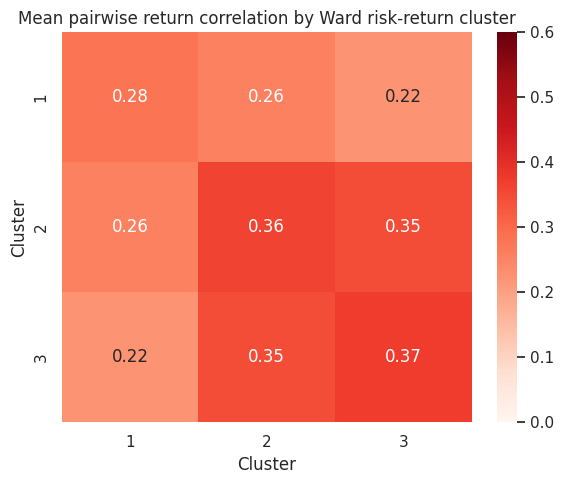

In [31]:
# B. Return dependencies within and between risk-return clusters
R = share_ret[common].corr()
lab = df["Ward_RR"]
dep = pd.DataFrame(index=sorted(lab.unique()), columns=sorted(lab.unique()), dtype=float)
for a in dep.index:
    for b in dep.columns:
        block = R.loc[lab[lab == a].index, lab[lab == b].index].to_numpy()
        if a == b:
            block = block[~np.eye(len(block), dtype=bool)]
        dep.loc[a, b] = np.nanmean(block)
print("Average pairwise weekly-return correlation, within (diagonal) and between Ward risk-return clusters:")
display(dep.round(3))
print(f"Average pairwise correlation across all shares: {R.to_numpy()[~np.eye(len(R), dtype=bool)].mean():.3f}")

# Does lower beta mean less shared movement? Average correlation of each share with all others.
avg_corr = (R.sum() - 1) / (len(R) - 1)
print(f"Spearman correlation between beta and a share's average correlation with others: "
      f"{stats.spearmanr(df['Weekly_Beta'], avg_corr.reindex(df.index))[0]:.3f}")
plt.figure(figsize=(6, 5))
sns.heatmap(dep.astype(float), annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=max(.6, dep.max().max()))
plt.title("Mean pairwise return correlation by Ward risk-return cluster")
plt.xlabel("Cluster"); plt.ylabel("Cluster")
plt.tight_layout(); savefig("fig13_return_dependencies"); plt.show()
dep.to_csv(f"{OUT_DIR}/return_dependencies_by_cluster.csv")

Days in the 60-session window with the most shares flagging an event:


,shares_with_event,% of shares
Date,,
2024-12-20,354,72.8
2024-11-06,156,32.1
2024-10-31,83,17.1
2024-11-25,76,15.6
2024-10-30,46,9.5
2024-11-15,42,8.6
2024-10-29,39,8.0
2024-11-07,38,7.8


Most common latest-event dates (these drive Recency):


,shares,% of common set,implied R (days)
Last_Event_Date,,,
2024-12-20,353,72.6,11
2024-11-25,17,3.5,36
2024-11-06,11,2.3,55
2024-11-01,6,1.2,60
2024-11-15,6,1.2,46


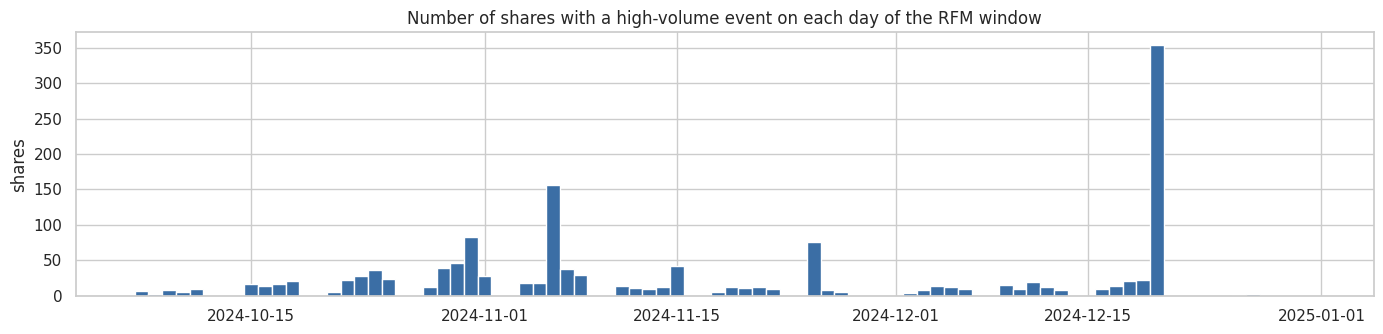

In [32]:
# C. Are high-volume events concentrated on market-wide dates?
ev_counts = event.loc[window].sum(axis=1)
top_days = ev_counts.sort_values(ascending=False).head(8)
print("Days in the 60-session window with the most shares flagging an event:")
display(pd.DataFrame({"shares_with_event": top_days, "% of shares": (top_days / len(included) * 100).round(1)}))
last_ev_share = df["Last_Event_Date"].value_counts().head(5)
print("Most common latest-event dates (these drive Recency):")
display(pd.DataFrame({"shares": last_ev_share, "% of common set": (last_ev_share / len(df) * 100).round(1),
                      "implied R (days)": [(obs_date - d).days for d in last_ev_share.index]}))
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(ev_counts.index, ev_counts.values, width=1.0, color="#3b6ea5")
ax.set(title="Number of shares with a high-volume event on each day of the RFM window", ylabel="shares")
plt.tight_layout(); savefig("fig14_event_concentration"); plt.show()

In [33]:
# D. Bootstrap stability of the selected Ward solutions (resample shares, refit, compare on overlap)
def ward_bootstrap(X, k, base_labels, B=100):
    rng = np.random.default_rng(SEED); scores = []
    for _ in range(B):
        idx = np.unique(rng.choice(len(X), size=len(X), replace=True))
        lab_b = cut_tree(linkage(X[idx], method="ward"), n_clusters=k).ravel() + 1
        scores.append(adjusted_rand_score(np.asarray(base_labels)[idx], lab_b))
    return np.mean(scores), np.percentile(scores, [5, 95])
def kmeans_bootstrap(X, k, base_labels, B=100):
    rng = np.random.default_rng(SEED); scores = []
    for _ in range(B):
        idx = np.unique(rng.choice(len(X), size=len(X), replace=True))
        lab_b = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=SEED).fit_predict(X[idx])
        scores.append(adjusted_rand_score(np.asarray(base_labels)[idx], lab_b))
    return np.mean(scores), np.percentile(scores, [5, 95])
boot = {}
for name, X, k, col, fn in [("Ward_RR", X_rr, K_WARD_RR, "Ward_RR", ward_bootstrap), ("Ward_RFM", X_rfm, K_WARD_RFM, "Ward_RFM", ward_bootstrap),
                            ("KMeans_RR", X_rr, K_KM_RR, "KMeans_RR", kmeans_bootstrap), ("KMeans_RFM", X_rfm, K_KM_RFM, "KMeans_RFM", kmeans_bootstrap)]:
    m, (lo, hi) = fn(X, k, df[col])
    boot[name] = {"mean_ARI": round(float(m), 3), "p5": round(float(lo), 3), "p95": round(float(hi), 3)}
print("Bootstrap stability (100 resamples of shares):", boot)

Bootstrap stability (100 resamples of shares): {'Ward_RR': {'mean_ARI': 0.352, 'p5': 0.107, 'p95': 0.623}, 'Ward_RFM': {'mean_ARI': 0.473, 'p5': 0.263, 'p95': 0.749}, 'KMeans_RR': {'mean_ARI': 0.874, 'p5': 0.655, 'p95': 0.99}, 'KMeans_RFM': {'mean_ARI': 0.932, 'p5': 0.786, 'p95': 1.0}}


In [34]:
# E. Survivorship: equal-weighted surviving constituents vs the index
ew = share_ret[common].mean(axis=1)
ann = lambda r: (1 + r).prod() ** (52 / len(r)) - 1
print(f"Equal-weighted surviving constituents: mean weekly {ew.mean()*100:.3f}%, annualised {ann(ew)*100:.1f}%")
print(f"^GSPC (price index):                    mean weekly {bench_ret.mean()*100:.3f}%, annualised {ann(bench_ret)*100:.1f}%")
print("Note: part of the gap is dividends (Adj Close vs price index) and equal vs cap weighting, not only survivorship.")

# F. What does Monetary measure? Relationship with price level and Frequency
price_level = close.loc[window, list(common)].mean()
print(f"Spearman: log1p(M) vs average share price in window: {stats.spearmanr(df['Log1p_Monetary'], price_level.reindex(df.index))[0]:.3f}")
print(f"Spearman: log1p(M) vs Frequency: {stats.spearmanr(df['Log1p_Monetary'], df['Frequency_days'])[0]:.3f}")
print("Top 10 shares by traded value:"); display((df["Monetary_USD"].sort_values(ascending=False).head(10) / 1e9).round(1).rename("M_$bn").to_frame())

critical = {"bootstrap": boot, "avg_pairwise_corr": float(R.to_numpy()[~np.eye(len(R), dtype=bool)].mean()),
            "top_event_day": str(top_days.index[0].date()), "top_event_day_pct": float(top_days.iloc[0] / len(included))}

Equal-weighted surviving constituents: mean weekly 0.286%, annualised 14.4%
^GSPC (price index):                    mean weekly 0.240%, annualised 11.8%
Note: part of the gap is dividends (Adj Close vs price index) and equal vs cap weighting, not only survivorship.
Spearman: log1p(M) vs average share price in window: 0.251
Spearman: log1p(M) vs Frequency: -0.048
Top 10 shares by traded value:


,M_$bn
Ticker,
TSLA,1847.7
NVDA,1825.3
AAPL,623.3
MSFT,534.9
AMZN,468.2
META,421.9
AVGO,334.0
AMD,313.2
GOOGL,294.4


## 3. Outputs for the Task 3 review

Sector composition of the selected Ward solutions, plus all exports needed for the GitHub repository.

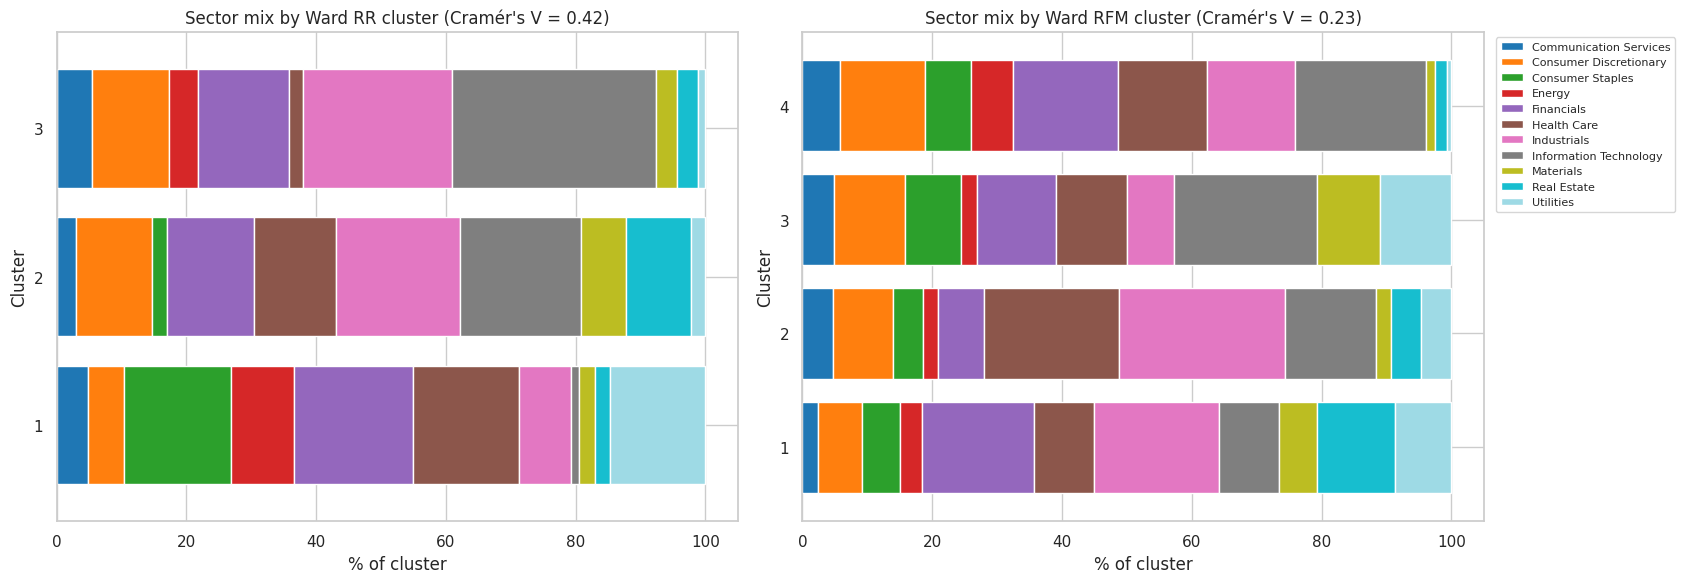

In [35]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct)[0]
    return np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, col in zip(axes, ["Ward_RR", "Ward_RFM"]):
    comp = pd.crosstab(df[col], df["Sector"], normalize="index") * 100
    comp.plot(kind="barh", stacked=True, ax=ax, colormap="tab20", width=.8, legend=(col == "Ward_RFM"))
    ax.set(title=f"Sector mix by {col.replace('_', ' ')} cluster (Cramér's V = {cramers_v(df[col], df['Sector']):.2f})",
           xlabel="% of cluster", ylabel="Cluster")
    pd.crosstab(df[col], df["Sector"], margins=True).to_csv(f"{OUT_DIR}/sector_composition_{col}.csv")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); savefig("fig12_sector_composition"); plt.show()

In [36]:
# ---- Prototype data mart in SQLite (Dimensional Fact Model, as in the SQLite RFM tutorial and DFM lecture) ----
import sqlite3
RUN_ID = f"run_{dt.datetime.now(dt.timezone.utc).strftime('%Y%m%dT%H%M%S')}"
conn = sqlite3.connect(f"{OUT_DIR}/sp500_datamart.sqlite")

dim_date = pd.DataFrame({"date_key": calendar.strftime("%Y%m%d").astype(int), "date": calendar.date,
                         "week_ending_fri": (calendar + pd.offsets.Week(weekday=4)).where(calendar.weekday != 4, calendar).date,
                         "month": calendar.month, "quarter": calendar.quarter, "year": calendar.year})
dim_share = constituents[["Ticker", "Security", "GICS Sector", "GICS Sub-Industry"]].rename(
    columns={"GICS Sector": "sector", "GICS Sub-Industry": "sub_industry"}) if "GICS Sub-Industry" in constituents else \
    constituents[["Ticker", "Security", "GICS Sector"]].rename(columns={"GICS Sector": "sector"})
dim_share["included"] = dim_share["Ticker"].isin(included).astype(int)
dim_benchmark = pd.DataFrame({"benchmark_key": [BENCHMARK], "name": ["S&P 500 price index"], "price_basis": ["Adj Close = Close (no dividends)"]})
dim_run = pd.DataFrame([{"run_id": RUN_ID, "source": meta.get("price_source"), "constituents_retrieved_utc": meta.get("constituents_retrieved_utc"),
                         "prices_downloaded_utc": meta.get("prices_downloaded_utc"), "study_start": START, "study_end_exclusive": END,
                         "observation_date": str(obs_date.date()), "rfm_window_start": str(window[0].date()),
                         "baseline_sessions": BASELINE_SESSIONS, "event_multiple": EVENT_MULTIPLE, "window_sessions": WINDOW_SESSIONS,
                         "seed": SEED, "kmeans_n_init": KMEANS_N_INIT, "code_version": "CW1 notebook v1", "versions": json.dumps(versions)}])

# Fact 1: daily share observations (grain = one share x one trading day)
fact_daily = (pd.concat({"adj_close": adj[included], "close": close[included], "volume": vol[included]}, axis=1)
              .stack(level=1, future_stack=True).rename_axis(["date", "Ticker"]).reset_index())
fact_daily["date_key"] = pd.to_datetime(fact_daily["date"]).dt.strftime("%Y%m%d").astype(int)
fact_daily["traded_value_usd"] = fact_daily["close"] * fact_daily["volume"]
fact_daily = fact_daily.drop(columns="date")

# Fact 2: derived share features (grain = one share x one run), Fact 3: cluster assignments (share x run x solution)
fact_features = df[["Aligned_weeks", "Mean_Weekly_Return", "Weekly_Beta", "Recency_days", "Frequency_days", "Monetary_USD"]].reset_index()
fact_features["run_id"] = RUN_ID
fact_clusters = df[["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM", "Ward_RF_only"]].reset_index().melt(
    id_vars="Ticker", var_name="solution", value_name="cluster")
fact_clusters["run_id"] = RUN_ID
fact_clusters["k"] = fact_clusters["solution"].map(df[["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM", "Ward_RF_only"]].nunique())

for name, tbl in [("dim_date", dim_date), ("dim_share", dim_share), ("dim_benchmark", dim_benchmark), ("dim_run", dim_run),
                  ("fact_daily", fact_daily), ("fact_share_features", fact_features), ("fact_cluster_assignment", fact_clusters)]:
    tbl.to_sql(name, conn, if_exists="replace", index=False)

# Example BI query: sector mix of each Ward RFM cluster, straight from the mart
q = '''
SELECT c.cluster, s.sector, COUNT(*) AS shares, ROUND(AVG(f.Monetary_USD)/1e9, 1) AS avg_traded_value_bn
FROM fact_cluster_assignment c
JOIN dim_share s ON s.Ticker = c.Ticker
JOIN fact_share_features f ON f.Ticker = c.Ticker AND f.run_id = c.run_id
WHERE c.solution = 'Ward_RFM'
GROUP BY c.cluster, s.sector ORDER BY c.cluster, shares DESC
'''
display(pd.read_sql(q, conn).head(15))
print("Tables:", pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)["name"].tolist())
conn.close()

# ---- Final exports ----
feature_table = df[["Security", "Sector", "Aligned_weeks", "Mean_Weekly_Return", "Weekly_Beta", "Weekly_Volatility",
                    "Last_Event_Date", "Recency_days", "Frequency_days", "Monetary_USD", "Log1p_Monetary",
                    "Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM", "Ward_RF_only"]]
feature_table.to_csv(f"{OUT_DIR}/feature_table_with_clusters.csv")
features.to_csv(f"{OUT_DIR}/feature_table_all_validated_shares.csv")   # includes shares without an event

run_meta = {
    **meta,
    "observation_date": str(obs_date.date()),
    "rfm_window": [str(window[0].date()), str(window[-1].date())],
    "weekly_returns": [str(bench_ret.index[0].date()), str(bench_ret.index[-1].date()), int(len(bench_ret))],
    "excluded_edge_weeks": [str(d.date()) for d in dropped_weeks],
    "n_constituents": len(tickers), "n_validated": len(included), "n_common": len(common),
    "selected_k": {"Ward_RR": K_WARD_RR, "KMeans_RR": K_KM_RR, "Ward_RFM": K_WARD_RFM, "KMeans_RFM": K_KM_RFM},
    "ARI": ari.round(4).to_dict(), "ARI_RFM_vs_RF_only": round(ari_m, 4),
    "kmeans_seed_stability": {k: round(v, 4) for k, v in stab.items()},
    "total_return_benchmark_check": tr_beta_check,
    "critical_checks": critical,
    "seed": SEED, "kmeans_n_init": KMEANS_N_INIT, "versions": versions,
}
json.dump(run_meta, open(f"{OUT_DIR}/run_metadata.json", "w"), indent=2, default=str)
print(json.dumps(run_meta, indent=2, default=str))
print("\nFiles in outputs/:", sorted(os.listdir(OUT_DIR)))

,cluster,sector,shares,avg_traded_value_bn
0,1,Industrials,40,11.3
1,1,Financials,36,10.4
2,1,Real Estate,25,9.7
3,1,Information Technology,19,11.2
4,1,Health Care,19,10.5
5,1,Utilities,18,10.4
6,1,Consumer Discretionary,14,13.8
7,1,Materials,12,12.0
8,1,Consumer Staples,12,11.9
9,1,Energy,7,17.6


Tables: ['dim_date', 'dim_share', 'dim_benchmark', 'dim_run', 'fact_daily', 'fact_share_features', 'fact_cluster_assignment']
{
  "constituents_source": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
  "constituents_retrieved_utc": "2026-11-18T05:36:51+00:00",
  "price_source": "Yahoo Finance via yfinance 0.2.66, auto_adjust=False, actions=True",
  "prices_downloaded_utc": "2026-11-18T05:38:12+00:00",
  "study_start": "2021-01-01",
  "study_end_exclusive": "2025-01-01",
  "observation_date": "2024-12-31",
  "rfm_window": [
    "2024-10-07",
    "2024-12-31"
  ],
  "weekly_returns": [
    "2021-01-15",
    "2024-12-27",
    207
  ],
  "excluded_edge_weeks": [
    "2025-01-03"
  ],
  "n_constituents": 503,
  "n_validated": 486,
  "n_common": 486,
  "selected_k": {
    "Ward_RR": 3,
    "KMeans_RR": 3,
    "Ward_RFM": 4,
    "KMeans_RFM": 4
  },
  "ARI": {
    "Ward vs K-means (risk-return)": 0.5164,
    "Ward vs K-means (RFM)": 0.343,
    "Risk-return vs RFM (Ward)": 0.0237

In [37]:
# ---- Download everything as a zip (Colab) to upload to GitHub ----
import shutil
shutil.make_archive("w2120567_outputs", "zip", root_dir=".", base_dir="outputs")
shutil.make_archive("w2120567_data", "zip", root_dir=".", base_dir="data")
try:
    from google.colab import files
    files.download("w2120567_outputs.zip"); files.download("w2120567_data.zip")
except ImportError:
    print("Not running in Colab: zips saved to the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>